In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
pd.options.mode.chained_assignment = None 

import h5py as h5 
from astropy import units as u
from astropy import constants as c
from astropy.cosmology import Planck18
from scipy.interpolate import interp1d

import os
import scipy

from collections import Counter
from collections import defaultdict
import gc

# from sklearn.utils import resample

pd.options.display.max_columns = None

In [2]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import matplotlib
from matplotlib.ticker import LogLocator, AutoMinorLocator, MultipleLocator
import matplotlib.ticker as ticker
import matplotlib.gridspec as gridspec

fontparams = {
    "font.family": "serif",
    "mathtext.fontset" : "stix",
    "grid.color": "gray",
    "grid.linestyle": ":",
    "axes.titlesize": "18",
    "axes.labelsize": "16",
    "xtick.labelsize": "16",
    "ytick.labelsize": "16",
    "xtick.labelbottom": "True",
    "legend.framealpha": "1",
}
rcParams.update(fontparams) 

%config InlineBackend.figure_format='retina' # very useful command for high-res images

from cycler import cycler

colorPalette = {'red': "#E64D4E",
                'orange': "#EE9063",
                'yellow': "#FFDD7B",
                'green': "#77AC54",
                'blue': "#0B92B1",
                'violet': "#665191",
                'gray': "#B4B4B4"
}

custom_cycler = (cycler(color=[colorPalette['red'], colorPalette['blue'], colorPalette['green']]))


In [3]:
pop_names = ['notides', 'realistic', 'perfect']
# pop_names = ['notides', 'realistic', 'perfect', 'z77']

pop_labels = {'notides': 'LEGACY',
              'realistic': 'KAPIL26',
              'perfect': 'PERFECT',
              'z77': 'Z77'}

pop_colors = {'notides': colorPalette['red'],
              'realistic': colorPalette['blue'],
              'perfect': colorPalette['green'],
             'z77': colorPalette['orange']}

pop_cmaps = {'notides': 'Reds',
              'realistic': 'Blues',
              'perfect': 'Greens'}

dco_types = ['BBH', 'BHNS', 'BNS']
dco_st = [28, 27, 26]
mt_labels = [
    "No MT", "Stable MT 1→2", "Stable MT 2→1", 
    "CE_Primary", "CE_Secondary", "CE_Both", "MT to Merger"
]
branching_labels = {1: 'Primary', 2: 'Secondary', 3: 'Both', 4: 'MT_to_Merger'}

plot_path = 'pop_plots/'

data_path = 'data_files/'

if not os.path.exists(plot_path):
   os.makedirs(plot_path)

In [4]:
pop_spin_dfs = {}
for pop_name in pop_names:
    pop_spin_dfs[pop_name] = pd.read_csv(data_path + pop_name+'_spin_df.csv') 

# Dimensionless Spin ($a_1, a_2$) Plots

LEGACY
Maximally spinning BBH primaries: 30 / 41813 (0.07%)
Maximally spinning BBH secondaries: 8660 / 41813 (20.71%)
Minimally spinning BBH primaries: 41070 / 41813 (98.22%)
Minimally spinning BBH secondaries: 12100 / 41813 (28.94%)

KAPIL26
Maximally spinning BBH primaries: 26 / 42592 (0.06%)
Maximally spinning BBH secondaries: 15459 / 42592 (36.30%)
Minimally spinning BBH primaries: 41972 / 42592 (98.54%)
Minimally spinning BBH secondaries: 15131 / 42592 (35.53%)

PERFECT
Maximally spinning BBH primaries: 32 / 44891 (0.07%)
Maximally spinning BBH secondaries: 8987 / 44891 (20.02%)
Minimally spinning BBH primaries: 44195 / 44891 (98.45%)
Minimally spinning BBH secondaries: 13370 / 44891 (29.78%)



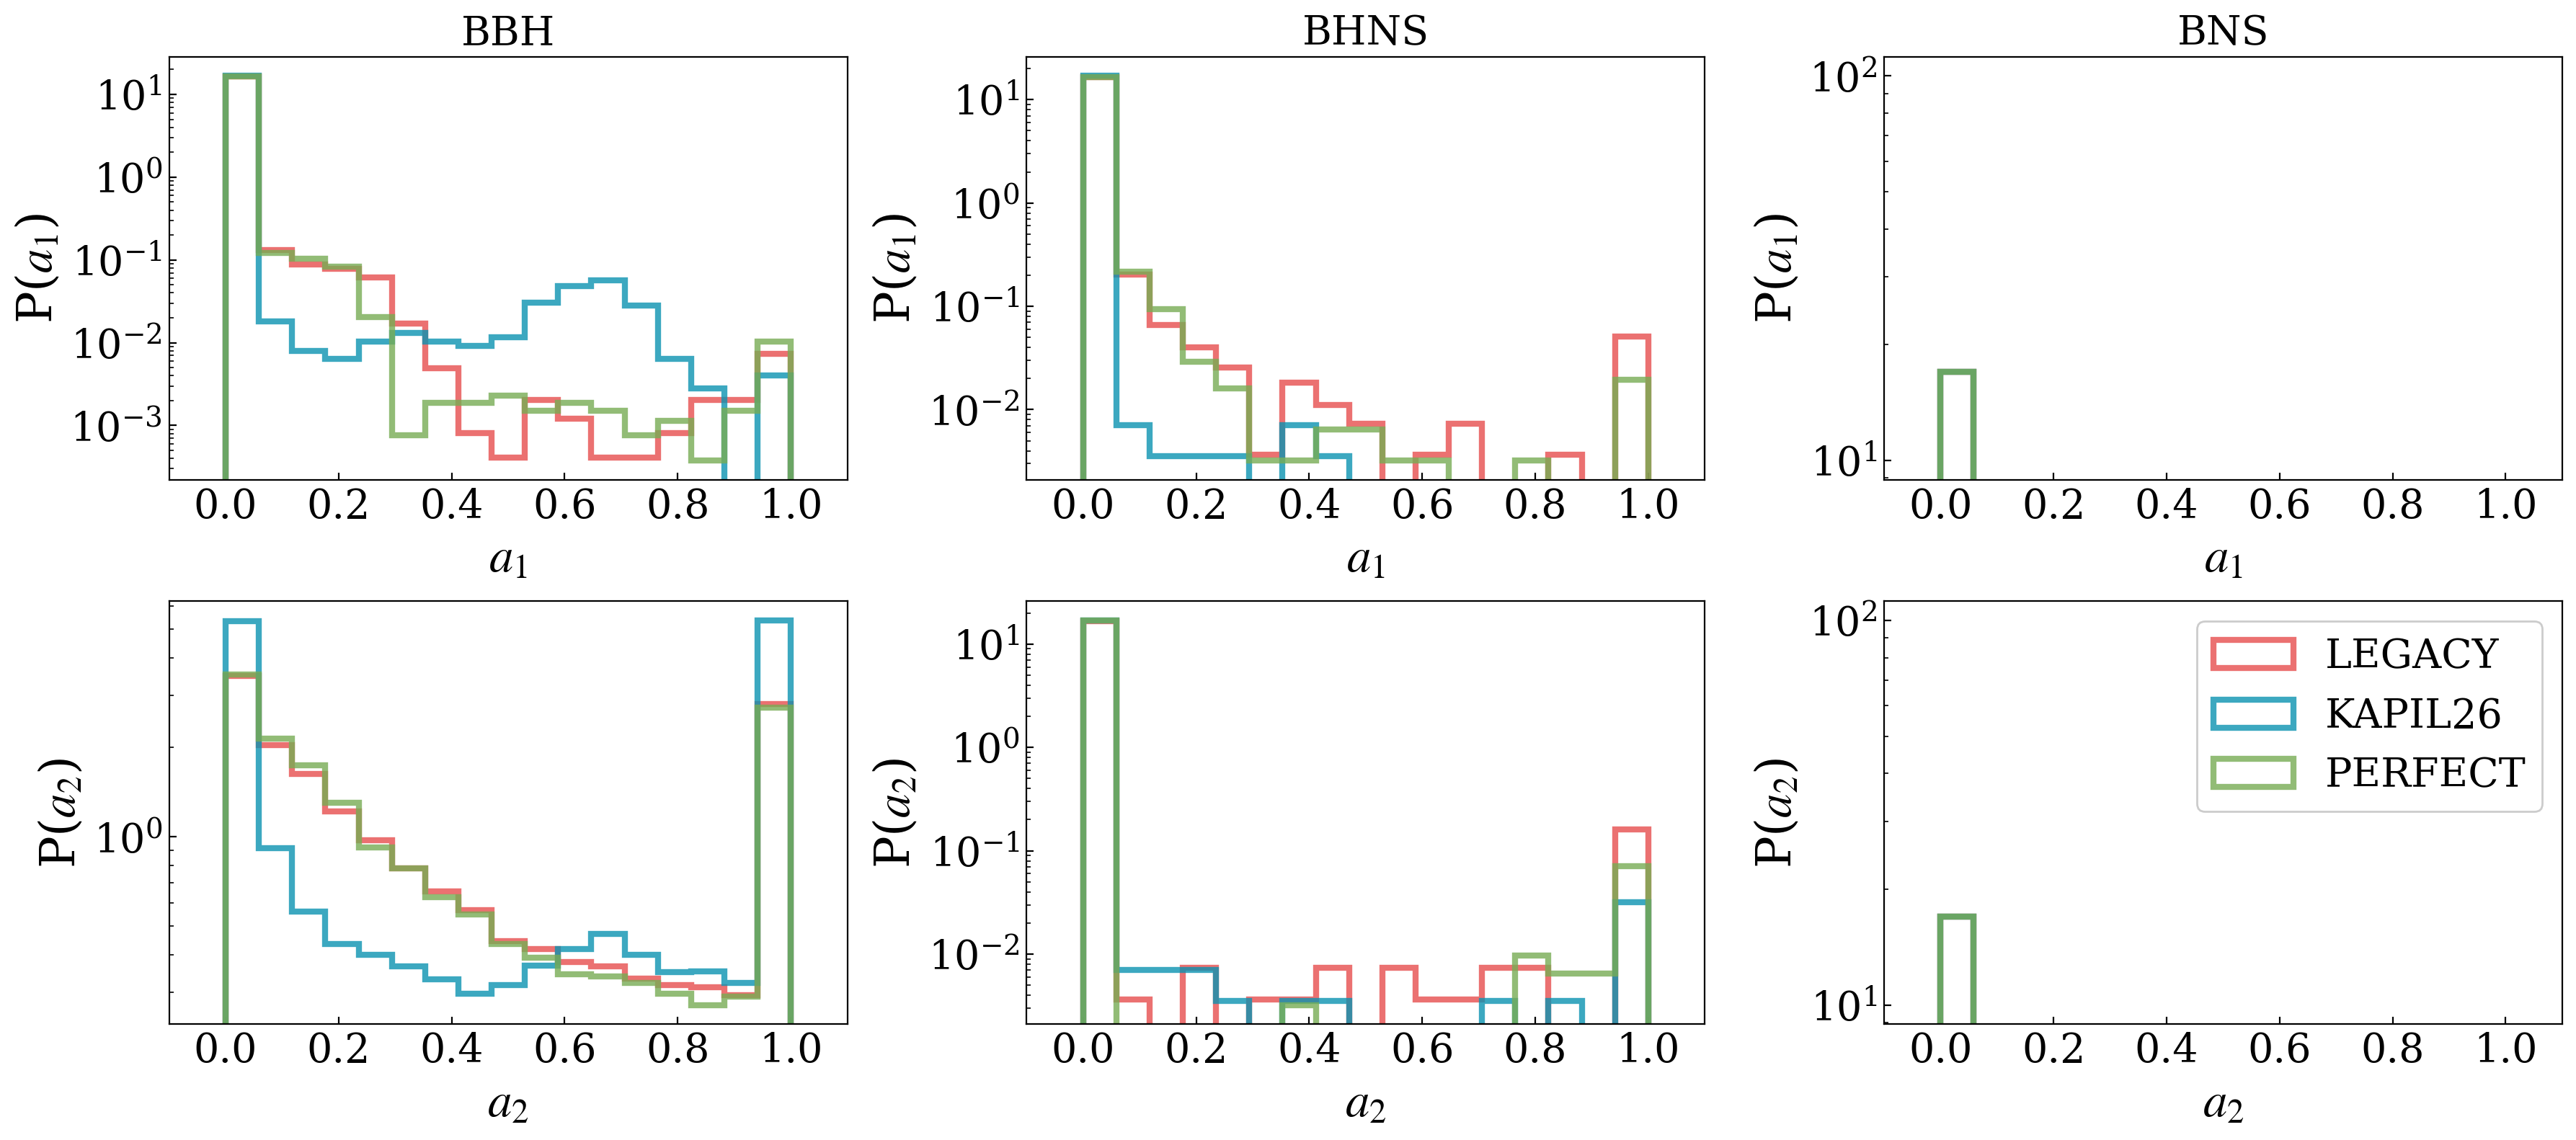

In [5]:
fig, axes = plt.subplots(ncols=3, nrows=2, figsize=(18,8))

for i, dco_type in enumerate(dco_types):
    for pop_name in pop_names:

        pop_spin_df = pop_spin_dfs[pop_name]
        pop_spin_df = pop_spin_df[(pop_spin_df[dco_type]==True) & (pop_spin_df["Merges_Hubble_Time"])]
        
        # pop_spin_omega_df = pop_spin_omega_dfs[pop_name]
        # pop_spin_omega_df = pop_spin_omega_df[(pop_spin_omega_df[dco_type]) & (pop_spin_omega_df["Merges_Hubble_Time"])]
        
        if pop_name == 'notides' or pop_name == 'perfect':
            a1, a2 = pop_spin_df["a1_orb"], pop_spin_df["a2_orb"]
        else:
            a1, a2 = pop_spin_df["a1"], pop_spin_df["a2"]

        bins = np.linspace(0, 1.0, 18)
        
        # a1, a2 = pop_spin_omega_df["a1"], pop_spin_omega_df["a2"]
        axes[0][i].hist(a1, bins=bins, density=True, alpha=0.8, histtype='step', lw=3, ls='-', label=pop_labels[pop_name], color=pop_colors[pop_name])
        axes[1][i].hist(a2, bins=bins, density=True, alpha=0.8, histtype='step', lw=3, ls='-', label=pop_labels[pop_name], color=pop_colors[pop_name])

        
        if dco_type == 'BBH':
            print(pop_labels[pop_name])
            print(f"Maximally spinning BBH primaries: {np.sum(a1>0.8)} / {len(a1)} ({100 * np.sum(a1>0.8)/len(a1):.2f}%)")
            print(f"Maximally spinning BBH secondaries: {np.sum(a2>0.8)} / {len(a2)} ({100 * np.sum(a2>0.8)/len(a2):.2f}%)")
            print(f"Minimally spinning BBH primaries: {np.sum(a1<0.1)} / {len(a1)} ({100 * np.sum(a1<0.1)/len(a1):.2f}%)")
            print(f"Minimally spinning BBH secondaries: {np.sum(a2<0.1)} / {len(a2)} ({100 * np.sum(a2<0.1)/len(a2):.2f}%)")
            print()

    axes[0][i].set_title(dco_type, fontsize=20)
    axes[0][i].set_xlabel('$a_{\\rm{1}}$', fontsize=24)
    axes[0][i].set_ylabel('P($a_1$)', fontsize=24)
    axes[0][i].set_yscale('log')
    # axes[0][i].legend(fontsize=20)

    axes[1][i].set_xlabel('$a_{\\rm{2}}$', fontsize=24)
    axes[1][i].set_ylabel('P($a_2$)', fontsize=24)
    axes[1][i].set_yscale('log')
    
    axes[0][i].set_xlim(-0.1,1.1)
    axes[1][i].set_xlim(-0.1,1.1)
    # axes[0][i].set_ylim(0, 6000)
    # axes[1][i].set_ylim(0, 6000)

    axes[0][i].tick_params(axis='both', which='major', labelsize=20)
    axes[1][i].tick_params(axis='both', which='major', labelsize=20)
    
    axes[0][i].set_xticks(ticks=np.linspace(0, 1, 6))
    axes[1][i].set_xticks(ticks=np.linspace(0, 1, 6))
    
    axes[0][i].tick_params(direction="in", which='both')
    axes[1][i].tick_params(direction="in", which='both')

    
    # axes[0][i].grid()
    # axes[1][i].grid()

# axes[0][2].legend(fontsize=20)
axes[1][2].legend(fontsize=20)

plt.tight_layout()
plt.show()

In [6]:
for pop_name in pop_names:
    print(pop_name)
    pop_df = pop_spin_dfs[pop_name]
    pop_df = pop_df[pop_df['BBH'] & pop_df['Merges_Hubble_Time']]
    n_total = len(pop_df)
    print(f"a1>0.8: {np.sum(pop_df['a1']>0.8)/n_total:.2f}, a2>0.8: {np.sum(pop_df['a2']>0.8)/n_total:.2f}")
    print(f"a1<0.1: {np.sum(pop_df['a1']<0.1)/n_total:.2f}, a2<0.1: {np.sum(pop_df['a2']<0.1)/n_total:.2f}")
    print(f"fallback_1>0.99: {np.sum(pop_df['fallback_1']>0.99)/n_total:.2f}, fallback_2>0.99: {np.sum(pop_df['fallback_2']>0.99)/n_total:.2f}")
    print(f"fallback_any>0.99: {(np.sum((pop_df['fallback_1']>0.99)) + np.sum(pop_df['fallback_2']>0.99))/(2*n_total):.2f}")

    print()

notides
a1>0.8: 0.00, a2>0.8: 0.00
a1<0.1: 0.98, a2<0.1: 0.90
fallback_1>0.99: 0.93, fallback_2>0.99: 0.77
fallback_any>0.99: 0.85

realistic
a1>0.8: 0.00, a2>0.8: 0.36
a1<0.1: 0.99, a2<0.1: 0.36
fallback_1>0.99: 0.94, fallback_2>0.99: 0.77
fallback_any>0.99: 0.85

perfect
a1>0.8: 0.00, a2>0.8: 0.26
a1<0.1: 0.98, a2<0.1: 0.20
fallback_1>0.99: 0.94, fallback_2>0.99: 0.77
fallback_any>0.99: 0.85



# Figure 5

LEGACY
Maximally spinning BBH primaries: 30 / 41813 (0.07%)
Maximally spinning BBH secondaries: 8660 / 41813 (20.71%)

KAPIL26
Maximally spinning BBH primaries: 26 / 42592 (0.06%)
Maximally spinning BBH secondaries: 15459 / 42592 (36.30%)

PERFECT
Maximally spinning BBH primaries: 32 / 44891 (0.07%)
Maximally spinning BBH secondaries: 8987 / 44891 (20.02%)



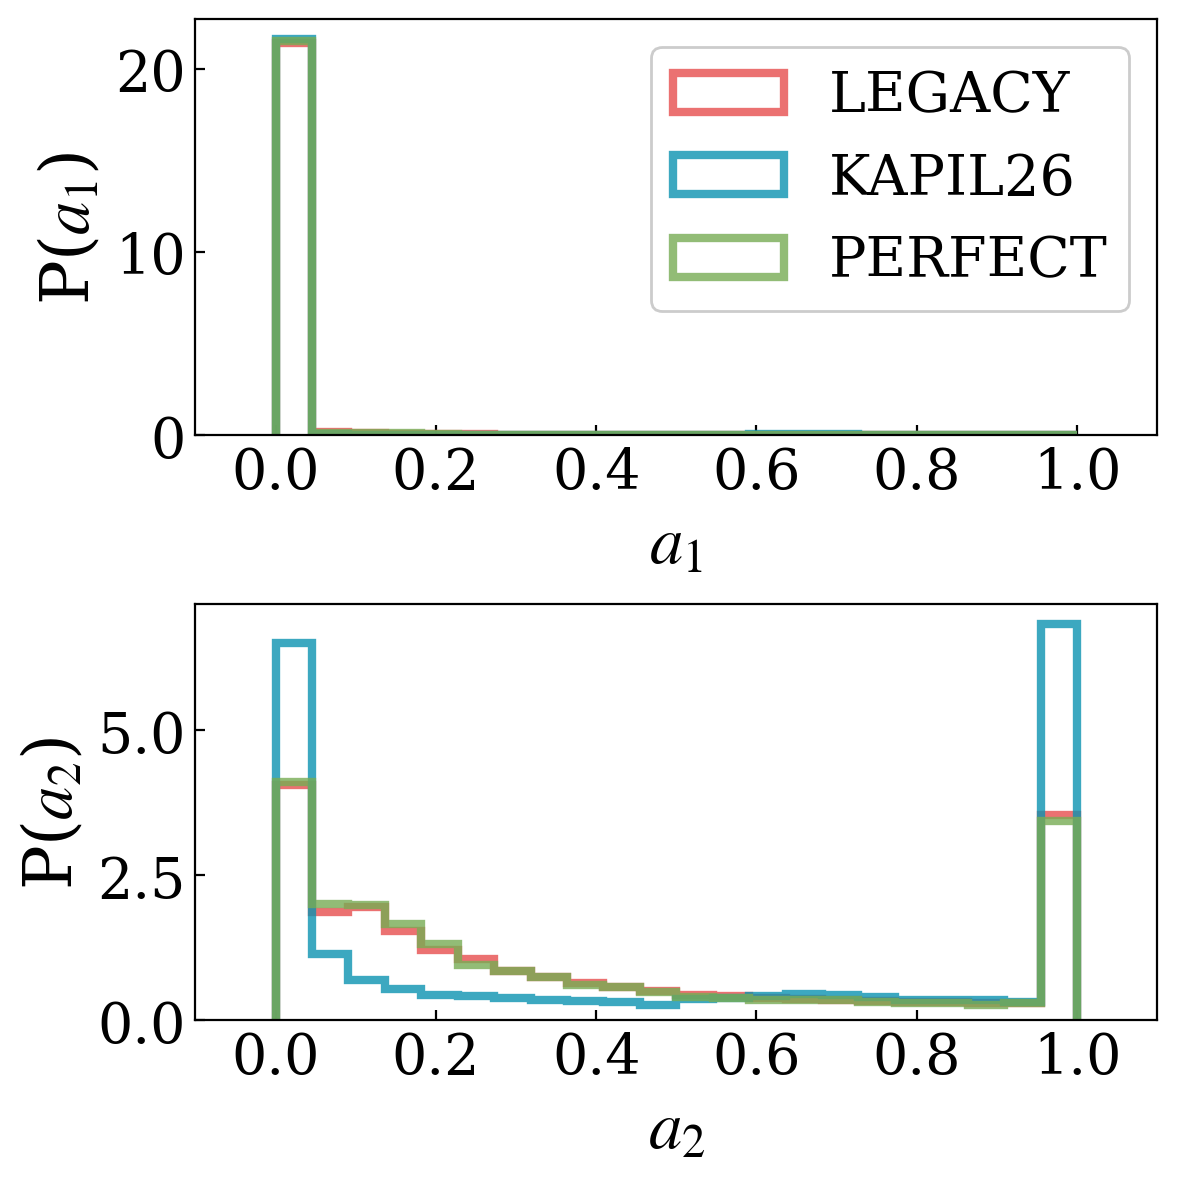

In [7]:
fig, axes = plt.subplots(ncols=1, nrows=2, figsize=(6,6), sharey=False)

dco_type = 'BBH'
# for pop_name in ['realistic', 'perfect']:
# for pop_name in ['notides', 'realistic']:
for pop_name in pop_names:
    pop_spin_df = pop_spin_dfs[pop_name]
    pop_spin_df = pop_spin_df[(pop_spin_df[dco_type]) & (pop_spin_df["Merges_Hubble_Time"])]

    m1, m2 = pop_spin_df["Mass@DCO(1)"], pop_spin_df["Mass@DCO(2)"]    

    if pop_name == 'notides' or pop_name == 'perfect':
            a1, a2 = pop_spin_df["a1_orb"], pop_spin_df["a2_orb"]
    else:
            a1, a2 = pop_spin_df["a1"], pop_spin_df["a2"]

    #  # Label by primary and secondary of DCO
    # invert_mask = m1 < m2
    # a1_relabeled, a2_relabeled = a1.copy(), a2.copy()
    # a1_relabeled[invert_mask], a2_relabeled[invert_mask] = a2[invert_mask], a1[invert_mask]
    # a1, a2 = a1_relabeled, a2_relabeled

    bins = np.linspace(0, 1.0, 23)
    axes[0].hist(a1, bins=bins, density=True, alpha=0.8, histtype='step', lw=3, ls='-', label=pop_labels[pop_name], color=pop_colors[pop_name])
    axes[1].hist(a2, bins=bins, density=True, alpha=0.8, histtype='step', lw=3, ls='-', label=pop_labels[pop_name], color=pop_colors[pop_name])

    
    if dco_type == 'BBH':
        print(pop_labels[pop_name])
        print(f"Maximally spinning BBH primaries: {np.sum(a1>0.8)} / {len(a1)} ({100 * np.sum(a1>0.8)/len(a1):.2f}%)")
        print(f"Maximally spinning BBH secondaries: {np.sum(a2>0.8)} / {len(a2)} ({100 * np.sum(a2>0.8)/len(a2):.2f}%)")
        print()

# axes[0].set_title(dco_type, fontsize=20)
axes[0].set_xlabel('$a_{\\rm{1}}$', fontsize=24)
axes[0].set_ylabel('P($a_1$)', fontsize=24)
# axes[0].set_yscale('log')
# axes[0].legend(fontsize=20)

axes[1].set_xlabel('$a_{\\rm{2}}$', fontsize=24)
axes[1].set_ylabel('P($a_2$)', fontsize=24)
# axes[1].set_yscale('log')

axes[0].set_xlim(-0.1,1.1)
axes[1].set_xlim(-0.1,1.1)
# axes[0].set_ylim(0, 6000)
# axes[1].set_ylim(0, 6000)

axes[0].tick_params(axis='both', direction='in', which='major', labelsize=20)
axes[1].tick_params(axis='both', direction='in', which='major', labelsize=20)

axes[0].set_xticks(ticks=np.linspace(0, 1, 6))
axes[1].set_xticks(ticks=np.linspace(0, 1, 6))


# axes[0].grid()
# axes[1].grid()

axes[0].legend(fontsize=20)

plt.tight_layout()
plt.savefig(plot_path+'a1_a2_dist.pdf', dpi=300, bbox_inches='tight')
plt.show()

# Figure 6

LEGACY
Maximally spinning BBH primaries: 2762 / 41813 (6.61%)
Maximally spinning BBH secondaries: 5928 / 41813 (14.18%)

KAPIL26
Maximally spinning BBH primaries: 8065 / 42592 (18.94%)
Maximally spinning BBH secondaries: 7420 / 42592 (17.42%)

PERFECT
Maximally spinning BBH primaries: 2451 / 44891 (5.46%)
Maximally spinning BBH secondaries: 6568 / 44891 (14.63%)



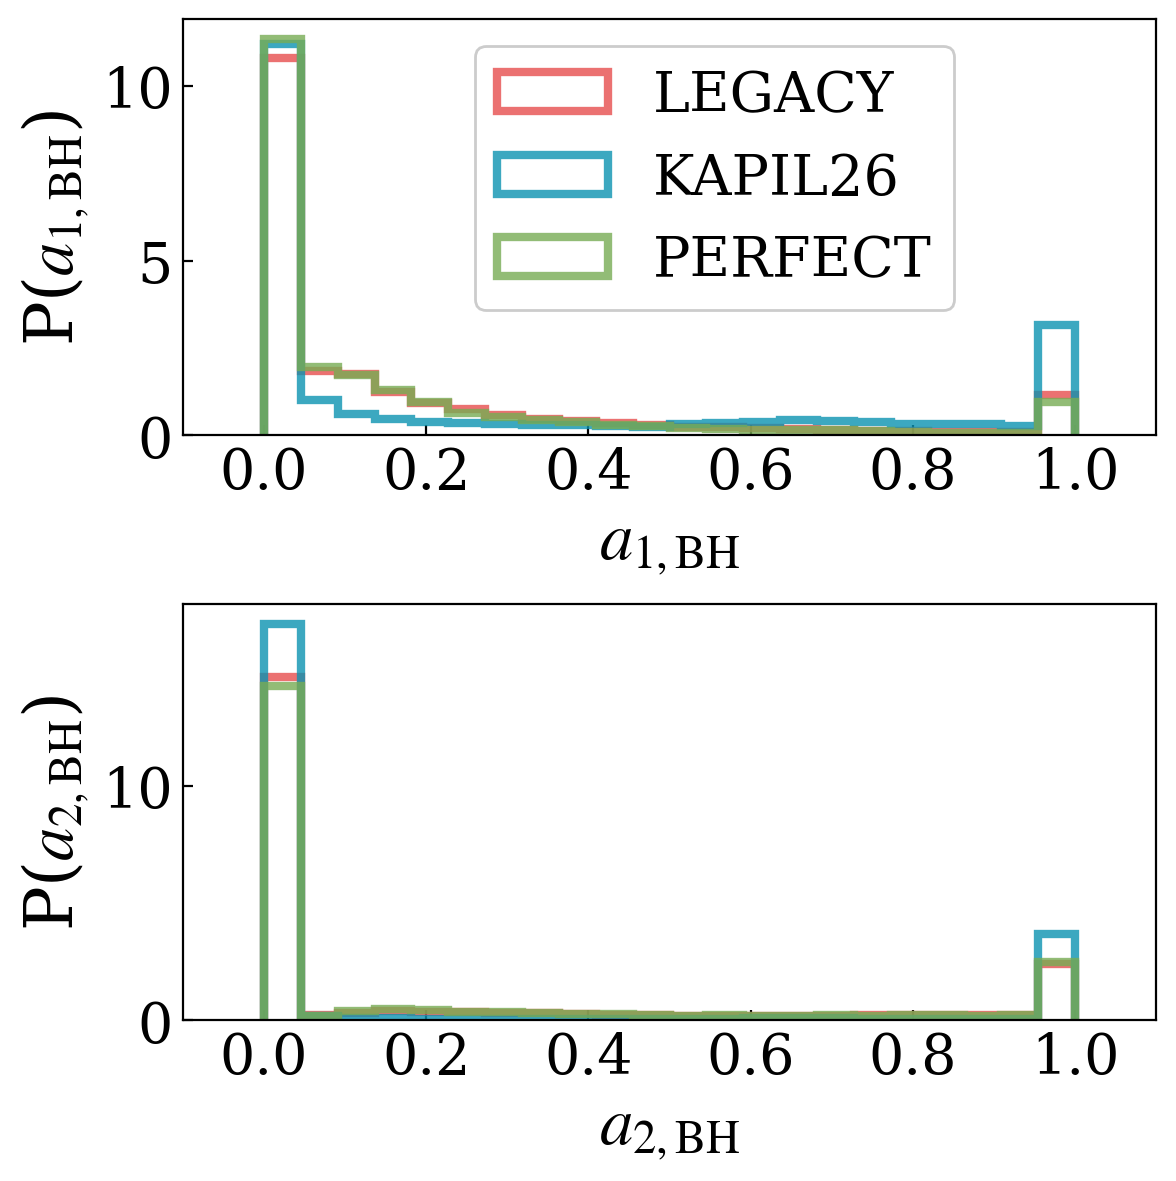

In [8]:
fig, axes = plt.subplots(ncols=1, nrows=2, figsize=(6,6), sharey=False)

dco_type = 'BBH'
# for pop_name in ['realistic', 'perfect']:
# for pop_name in ['notides', 'realistic']:
for pop_name in pop_names:
    pop_spin_df = pop_spin_dfs[pop_name]
    pop_spin_df = pop_spin_df[(pop_spin_df[dco_type]) & (pop_spin_df["Merges_Hubble_Time"])]

    m1, m2 = pop_spin_df["Mass@DCO(1)"], pop_spin_df["Mass@DCO(2)"]    
    
    if pop_name == 'notides' or pop_name == 'perfect':
            a1, a2 = pop_spin_df["a1_orb"], pop_spin_df["a2_orb"]
    else:
            a1, a2 = pop_spin_df["a1"], pop_spin_df["a2"]

     # Label by primary and secondary of DCO
    invert_mask = m1 < m2
    a1_relabeled, a2_relabeled = a1.copy(), a2.copy()
    a1_relabeled[invert_mask], a2_relabeled[invert_mask] = a2[invert_mask], a1[invert_mask]
    a1, a2 = a1_relabeled, a2_relabeled

    bins = np.linspace(0, 1.0, 23)
    axes[0].hist(a1, bins=bins, density=True, alpha=0.8, histtype='step', lw=3, ls='-', label=pop_labels[pop_name], color=pop_colors[pop_name])
    axes[1].hist(a2, bins=bins, density=True, alpha=0.8, histtype='step', lw=3, ls='-', label=pop_labels[pop_name], color=pop_colors[pop_name])

    
    if dco_type == 'BBH':
        print(pop_labels[pop_name])
        print(f"Maximally spinning BBH primaries: {np.sum(a1>0.8)} / {len(a1)} ({100 * np.sum(a1>0.8)/len(a1):.2f}%)")
        print(f"Maximally spinning BBH secondaries: {np.sum(a2>0.8)} / {len(a2)} ({100 * np.sum(a2>0.8)/len(a2):.2f}%)")
        print()

# axes[0].set_title(dco_type, fontsize=20)
axes[0].set_xlabel('$a_{\\rm{1, BH}}$', fontsize=24)
axes[0].set_ylabel('P($a_{\\rm{1, BH}}$)', fontsize=24)
# axes[0].set_yscale('log')
# axes[0].legend(fontsize=20)

axes[1].set_xlabel('$a_{\\rm{2, BH}}$', fontsize=24)
axes[1].set_ylabel('P($a_{\\rm{2, BH}}$)', fontsize=24)
# axes[1].set_yscale('log')

axes[0].set_xlim(-0.1,1.1)
axes[1].set_xlim(-0.1,1.1)
# axes[0].set_ylim(0, 6000)
# axes[1].set_ylim(0, 6000)

axes[0].tick_params(axis='both', direction='in', which='major', labelsize=20)
axes[1].tick_params(axis='both', direction='in', which='major', labelsize=20)

axes[0].set_xticks(ticks=np.linspace(0, 1, 6))
axes[1].set_xticks(ticks=np.linspace(0, 1, 6))


# axes[0].grid()
# axes[1].grid()

axes[0].legend(loc=(0.3, 0.3), fontsize=20)

plt.tight_layout()
plt.savefig(plot_path+'a1_a2_dist_dco_labels.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [9]:
for pop_name in pop_names:
    pop_spin_df = pop_spin_dfs[pop_name]
    pop_spin_df = pop_spin_df[(pop_spin_df[dco_type]) & (pop_spin_df["Merges_Hubble_Time"])]
    invert_mask = pop_spin_df["Mass@DCO(1)"] < pop_spin_df["Mass@DCO(2)"]    
    print(f"{pop_name} Mass ratio reversal: {np.sum(invert_mask)} out of {len(pop_spin_df)} BBHs")

notides Mass ratio reversal: 21416 out of 41813 BBHs
realistic Mass ratio reversal: 22328 out of 42592 BBHs
perfect Mass ratio reversal: 21959 out of 44891 BBHs


## Old investigations

### Which SMT binaries have higher secondary spin with K26 than perfect tides?


Answer: when the primary undergoes stable RLOF on HG, spins up the secondary, and tides cannot spin it down fast enough.

In [10]:
notides_smt_fb2 = pop_spin_dfs['notides'][(pop_spin_dfs['notides']['BBH']) & (pop_spin_dfs['notides']['Merges_Hubble_Time']) & (~pop_spin_dfs['notides']['CE_Secondary']) & (pop_spin_dfs['notides']['fallback_2'] > 0.1)]
realistic_smt_fb2 = pop_spin_dfs['realistic'][(pop_spin_dfs['realistic']['BBH']) & (pop_spin_dfs['realistic']['Merges_Hubble_Time']) & (~pop_spin_dfs['realistic']['CE_Secondary']) &(pop_spin_dfs['realistic']['fallback_2'] > 0.1)]
perfect_smt_fb2 = pop_spin_dfs['perfect'][(pop_spin_dfs['perfect']['BBH']) & (pop_spin_dfs['perfect']['Merges_Hubble_Time']) & (~pop_spin_dfs['perfect']['CE_Secondary']) &(pop_spin_dfs['perfect']['fallback_2'] > 0.1)]

notides_realistic = notides_smt_fb2.join(realistic_smt_fb2.set_index('SEED'), on='SEED', lsuffix='_notides', rsuffix='_realistic', how='inner')
notides_realistic_perfect = notides_realistic.join(perfect_smt_fb2.set_index('SEED'), on='SEED', lsuffix='', rsuffix='_perfect', how='inner')

notides_realistic_perfect[['SEED', 'chi_eff_notides', 'chi_eff_realistic', 'chi_eff']]

,SEED,chi_eff_notides,chi_eff_realistic,chi_eff
2,126083,0.014341,0.620599,0.071870
8,126181,0.011564,0.095320,0.186103
13,126307,0.087878,0.414772,0.262043
19,126584,0.001165,0.061123,0.076254
25,126732,0.008174,0.609066,0.100732
...,...,...,...,...
141009,1219336,0.107344,0.405827,0.431684
141014,1219462,0.042531,0.229365,0.142018
141016,1219536,0.184865,0.592283,0.394238
141018,1219586,0.000911,0.163912,0.149410


In [11]:
perfect_seeds = pop_spin_dfs['perfect']['SEED'][pop_spin_dfs['perfect']['Merges_Hubble_Time'] & pop_spin_dfs['perfect']['BBH'] & (pop_spin_dfs['perfect']['RLOF_Primary'])]
realistic_seeds = pop_spin_dfs['realistic']['SEED'][pop_spin_dfs['realistic']['Merges_Hubble_Time'] & pop_spin_dfs['realistic']['BBH'] & (pop_spin_dfs['realistic']['RLOF_Primary'])]

both_seeds_mask = np.isin(perfect_seeds, realistic_seeds)
a2_realistic = pop_spin_dfs['realistic'][pop_spin_dfs['realistic']['SEED'].isin(perfect_seeds[both_seeds_mask])]['a2'].values
a2_perfect = pop_spin_dfs['perfect'][pop_spin_dfs['perfect']['SEED'].isin(perfect_seeds[both_seeds_mask])]['a2'].values

In [12]:
pop_spin_dfs['realistic'][pop_spin_dfs['realistic']['SEED'].isin(perfect_seeds[both_seeds_mask])][a2_realistic > a2_perfect].head()

,SEED,Mass@ZAMS(1),Mass@ZAMS(2),Metallicity@ZAMS(1),Omega(1),Omega(2),Eccentricity@ZAMS,SemiMajorAxis@ZAMS,CH_on_MS(1),CH_on_MS(2),Mass@DCO(1),Mass@DCO(2),SemiMajorAxis@DCO,Eccentricity@DCO,Stellar_Type(1),Stellar_Type(2),Merges_Hubble_Time,Time@DCO,Coalescence_Time,M_min@DCO,M_max@DCO,Ang_Momentum(SN)_Primary,Ang_Momentum(SN)_Secondary,Ang_Momentum(SN)_Both,MT_Donor_Hist(SN)_Primary,MT_Donor_Hist(SN)_Secondary,Mass(CP)_Primary,Mass(CP)_Secondary,Mass(CP)_Both,Mass(SN)_Primary,Mass(SN)_Secondary,Mass(SN)_Both,Mass_CO_Core@CO(SN)_Primary,Mass_CO_Core@CO(SN)_Secondary,Mass_CO_Core@CO(SN)_Both,Mass_Core@CO(SN)_Primary,Mass_Core@CO(SN)_Secondary,Mass_Core@CO(SN)_Both,Mass_Total@CO(SN)_Primary,Mass_Total@CO(SN)_Secondary,Mass_Total@CO(SN)_Both,Number_of_RLOF(SN)_Primary,Number_of_RLOF(SN)_Secondary,Number_of_RLOF(SN)_Both,Omega(SN)_Primary,Omega(SN)_Secondary,Omega(SN)_Both,Orbital_Period<SN_Primary,Orbital_Period<SN_Secondary,Orbital_Period<SN_Both,RLOF_Primary,RLOF_Secondary,RLOF_Both,Radius_Core@CO(SN)_Primary,Radius_Core@CO(SN)_Secondary,Radius_Core@CO(SN)_Both,Radius_Total@CO(SN)_Primary,Radius_Total@CO(SN)_Secondary,Radius_Total@CO(SN)_Both,SN_Orbit_Inclination_Angle_Primary,SN_Orbit_Inclination_Angle_Secondary,SN_Orbit_Inclination_Angle_Both,SN_Type(SN)_Primary,SN_Type(SN)_Secondary,SN_Type(SN)_Both,SemiMajorAxis<SN_Primary,SemiMajorAxis<SN_Secondary,SemiMajorAxis<SN_Both,Stellar_Type_Prev(SN)_Primary,Stellar_Type_Prev(SN)_Secondary,Stellar_Type_Prev(SN)_Both,Time@SN_Primary,Time@SN_Secondary,Time@SN_Both,Eccentricity<CE_Primary,Eccentricity<CE_Secondary,Eccentricity<CE_Both,Mass(1)<CE_Primary,Mass(1)<CE_Secondary,Mass(1)<CE_Both,Mass(2)<CE_Primary,Mass(2)<CE_Secondary,Mass(2)<CE_Both,SemiMajorAxis<CE_Primary,SemiMajorAxis<CE_Secondary,SemiMajorAxis<CE_Both,Stellar_Type(1)<CE_Primary,Stellar_Type(1)<CE_Secondary,Stellar_Type(1)<CE_Both,Stellar_Type(1)>CE_Primary,Stellar_Type(1)>CE_Secondary,Stellar_Type(1)>CE_Both,Stellar_Type(2)<CE_Primary,Stellar_Type(2)<CE_Secondary,Stellar_Type(2)<CE_Both,Stellar_Type(2)>CE_Primary,Stellar_Type(2)>CE_Secondary,Stellar_Type(2)>CE_Both,Time@CE_Primary,Time@CE_Secondary,Time@CE_Both,CE_Primary,CE_Secondary,CE_Both,BBH,BHNS,BNS,a1,a2,a1_orb,a2_orb,fallback_1,fallback_2,iota1,iota2,chi_eff,chi_eff_orb
4,268175,35.970528,31.892628,0.000298,16.275098,16313.552933,0.446782,0.417998,False,False,11.720881,20.454058,0.030001,1.110223e-16,14,14,True,8.217540,33.767174,11.720881,20.454058,1.258884e-04,0.685135,NaN,[2],[2],54.247143,11.720881,NaN,11.720621,20.454058,NaN,8.716394,15.607909,NaN,8.716394,15.607909,NaN,11.720621,20.454058,NaN,1.0,1.0,NaN,15.931075,16313.552933,NaN,17.355648,0.334615,NaN,True,True,True,0.000071,0.000071,NaN,1.125913,1.450845,NaN,0.0,0.0,NaN,1.0,1.0,NaN,0.530077,0.030001,NaN,8.0,8.0,NaN,6.301027,8.217540,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,True,False,False,1.467983e-03,1.000000,0.012700,0.579366,1.0,1.000000,0.0,0.0,0.636249,0.372938
7,268292,59.316726,57.889802,0.000442,5.107528,2937.212016,0.373777,0.454649,False,False,21.322554,35.292025,0.078961,4.279514e-03,14,14,True,5.963685,293.342182,21.322554,35.292025,2.351290e-04,0.633656,NaN,"[1, 2]",[2],87.900613,21.322554,NaN,21.322136,35.292025,NaN,16.353222,28.715953,NaN,16.353222,28.715953,NaN,21.322136,35.534307,NaN,2.0,1.0,NaN,4.942256,2937.212016,NaN,16.278758,1.067898,NaN,True,True,True,0.000071,0.000071,NaN,1.487958,2.019264,NaN,0.0,0.0,NaN,1.0,8.0,NaN,0.600878,0.078623,NaN,8.0,8.0,NaN,4.670523,5.963685,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,True,False,False,8.284832e-04,0.661064,0.011819,0.160284,1.0,0.964466,0.0,0.0,0.412402,0.104368
10,268443,51.219762,35.626520,0.000101,17.430205,759.205604,0.033486,0.358484,False,False,18.912368,26.086924,0.122695,2.220446e-16,14,14,True,7.235667,3281.996774,18.912368,26.086924,5.719263e-04,0.06614

In [13]:
pop_spin_dfs['perfect'][pop_spin_dfs['perfect']['SEED'].isin(perfect_seeds[both_seeds_mask])][a2_realistic > a2_perfect].head()

,SEED,Mass@ZAMS(1),Mass@ZAMS(2),Metallicity@ZAMS(1),Omega(1),Omega(2),Eccentricity@ZAMS,SemiMajorAxis@ZAMS,CH_on_MS(1),CH_on_MS(2),Mass@DCO(1),Mass@DCO(2),SemiMajorAxis@DCO,Eccentricity@DCO,Stellar_Type(1),Stellar_Type(2),Merges_Hubble_Time,Time@DCO,Coalescence_Time,M_min@DCO,M_max@DCO,Ang_Momentum(SN)_Primary,Ang_Momentum(SN)_Secondary,Ang_Momentum(SN)_Both,MT_Donor_Hist(SN)_Primary,MT_Donor_Hist(SN)_Secondary,Mass(CP)_Primary,Mass(CP)_Secondary,Mass(CP)_Both,Mass(SN)_Primary,Mass(SN)_Secondary,Mass(SN)_Both,Mass_CO_Core@CO(SN)_Primary,Mass_CO_Core@CO(SN)_Secondary,Mass_CO_Core@CO(SN)_Both,Mass_Core@CO(SN)_Primary,Mass_Core@CO(SN)_Secondary,Mass_Core@CO(SN)_Both,Mass_Total@CO(SN)_Primary,Mass_Total@CO(SN)_Secondary,Mass_Total@CO(SN)_Both,Number_of_RLOF(SN)_Primary,Number_of_RLOF(SN)_Secondary,Number_of_RLOF(SN)_Both,Omega(SN)_Primary,Omega(SN)_Secondary,Omega(SN)_Both,Orbital_Period<SN_Primary,Orbital_Period<SN_Secondary,Orbital_Period<SN_Both,RLOF_Primary,RLOF_Secondary,RLOF_Both,Radius_Core@CO(SN)_Primary,Radius_Core@CO(SN)_Secondary,Radius_Core@CO(SN)_Both,Radius_Total@CO(SN)_Primary,Radius_Total@CO(SN)_Secondary,Radius_Total@CO(SN)_Both,SN_Orbit_Inclination_Angle_Primary,SN_Orbit_Inclination_Angle_Secondary,SN_Orbit_Inclination_Angle_Both,SN_Type(SN)_Primary,SN_Type(SN)_Secondary,SN_Type(SN)_Both,SemiMajorAxis<SN_Primary,SemiMajorAxis<SN_Secondary,SemiMajorAxis<SN_Both,Stellar_Type_Prev(SN)_Primary,Stellar_Type_Prev(SN)_Secondary,Stellar_Type_Prev(SN)_Both,Time@SN_Primary,Time@SN_Secondary,Time@SN_Both,Eccentricity<CE_Primary,Eccentricity<CE_Secondary,Eccentricity<CE_Both,Mass(1)<CE_Primary,Mass(1)<CE_Secondary,Mass(1)<CE_Both,Mass(2)<CE_Primary,Mass(2)<CE_Secondary,Mass(2)<CE_Both,SemiMajorAxis<CE_Primary,SemiMajorAxis<CE_Secondary,SemiMajorAxis<CE_Both,Stellar_Type(1)<CE_Primary,Stellar_Type(1)<CE_Secondary,Stellar_Type(1)<CE_Both,Stellar_Type(1)>CE_Primary,Stellar_Type(1)>CE_Secondary,Stellar_Type(1)>CE_Both,Stellar_Type(2)<CE_Primary,Stellar_Type(2)<CE_Secondary,Stellar_Type(2)<CE_Both,Stellar_Type(2)>CE_Primary,Stellar_Type(2)>CE_Secondary,Stellar_Type(2)>CE_Both,Time@CE_Primary,Time@CE_Secondary,Time@CE_Both,CE_Primary,CE_Secondary,CE_Both,BBH,BHNS,BNS,a1,a2,a1_orb,a2_orb,fallback_1,fallback_2,iota1,iota2,chi_eff,chi_eff_orb
0,294012,35.034678,30.197647,0.002735,0.000102,0.000102,0.166630,5.718153,False,False,11.550039,10.516661,0.043784,0.0,14,14,True,7.454090,440.823199,10.516661,11.550039,0.000005,0.022606,NaN,[4],[4],29.776833,11.550039,NaN,11.550039,10.516661,NaN,8.587839,7.788181,NaN,8.587839,7.788181,NaN,11.550039,10.516661,NaN,1.0,1.0,NaN,0.673922,3959.968815,NaN,3619.955401,0.710945,NaN,True,True,True,0.000071,0.000071,NaN,1.120439,1.089767,NaN,0.0,0.000000,NaN,1.0,1.0,NaN,15.951960,0.043726,NaN,8.0,8.0,NaN,6.500372,7.454090,NaN,NaN,0.0,NaN,NaN,11.550039,NaN,NaN,28.020533,NaN,NaN,3284.087528,NaN,NaN,14.0,NaN,NaN,14.0,NaN,NaN,4.0,NaN,NaN,7.0,NaN,NaN,7.070653,NaN,False,True,False,True,False,False,0.000061,3.274269e-01,0.000061,3.276537e-01,1.0,1.0,0.0,0.000000,0.156079,0.156187
1,294113,36.886617,30.351267,0.002155,0.000057,0.000057,0.022303,0.393531,False,False,11.541902,18.251683,0.071582,0.0,14,14,True,8.473498,1344.999561,11.541902,18.251683,0.000345,0.032162,NaN,[2],[2],51.932402,11.541902,NaN,11.541746,18.251683,NaN,8.580881,13.794702,NaN,8.580881,13.794702,NaN,11.541746,18.251683,NaN,1.0,1.0,NaN,45.769074,1077.823961,NaN,53.374472,1.279675,NaN,True,True,True,0.000071,0.000071,NaN,1.120231,1.361622,NaN,0.0,0.000000,NaN,1.0,1.0,NaN,1.106681,0.071511,NaN,8.0,8.0,NaN,6.278908,8.473498,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,True,False,False,0.004153,1.546662e-01,0.004155,1.541231e-01,1.0,1.0,0.0,0.000000,0.096358,0.096026
3,294147,34.700058,18.881717,0.009933,0.000130,0.000130,0.503259,3.760529,False,False,10.158709,4.129705,0.032249,0.0,14,14,True,11.171482,580.158323,4.129705,10.158709,0.000022,0.032736,NaN,[2],[4],

When Star 1 goes from HG to HeMS, it does it by overflowing its roche lobe and transferring a lot of mass on to Star 2. Star 2 accretes this mass and spins up, since the angular momentum is added coherently from the surface of accretion. 

Perfect tides can immediately dispel the extra angular momentum back into the orbit via tidal forces, whereas realistic tides cannot efficiently widen the binary to account for this 'extra' angular momentum stored in star 2. This difference persists until the secondary goes through SN, at which point the secondary with realistic tides is still rapidly rotating while the secondary with perfect tides is slower.

This should be true mostly for binaries where the primary goes through stable MT while on HG. Let's check:

/home/vkapil1/.conda/envs/tides/lib/python3.9/site-packages/numpy/lib/histograms.py:885: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


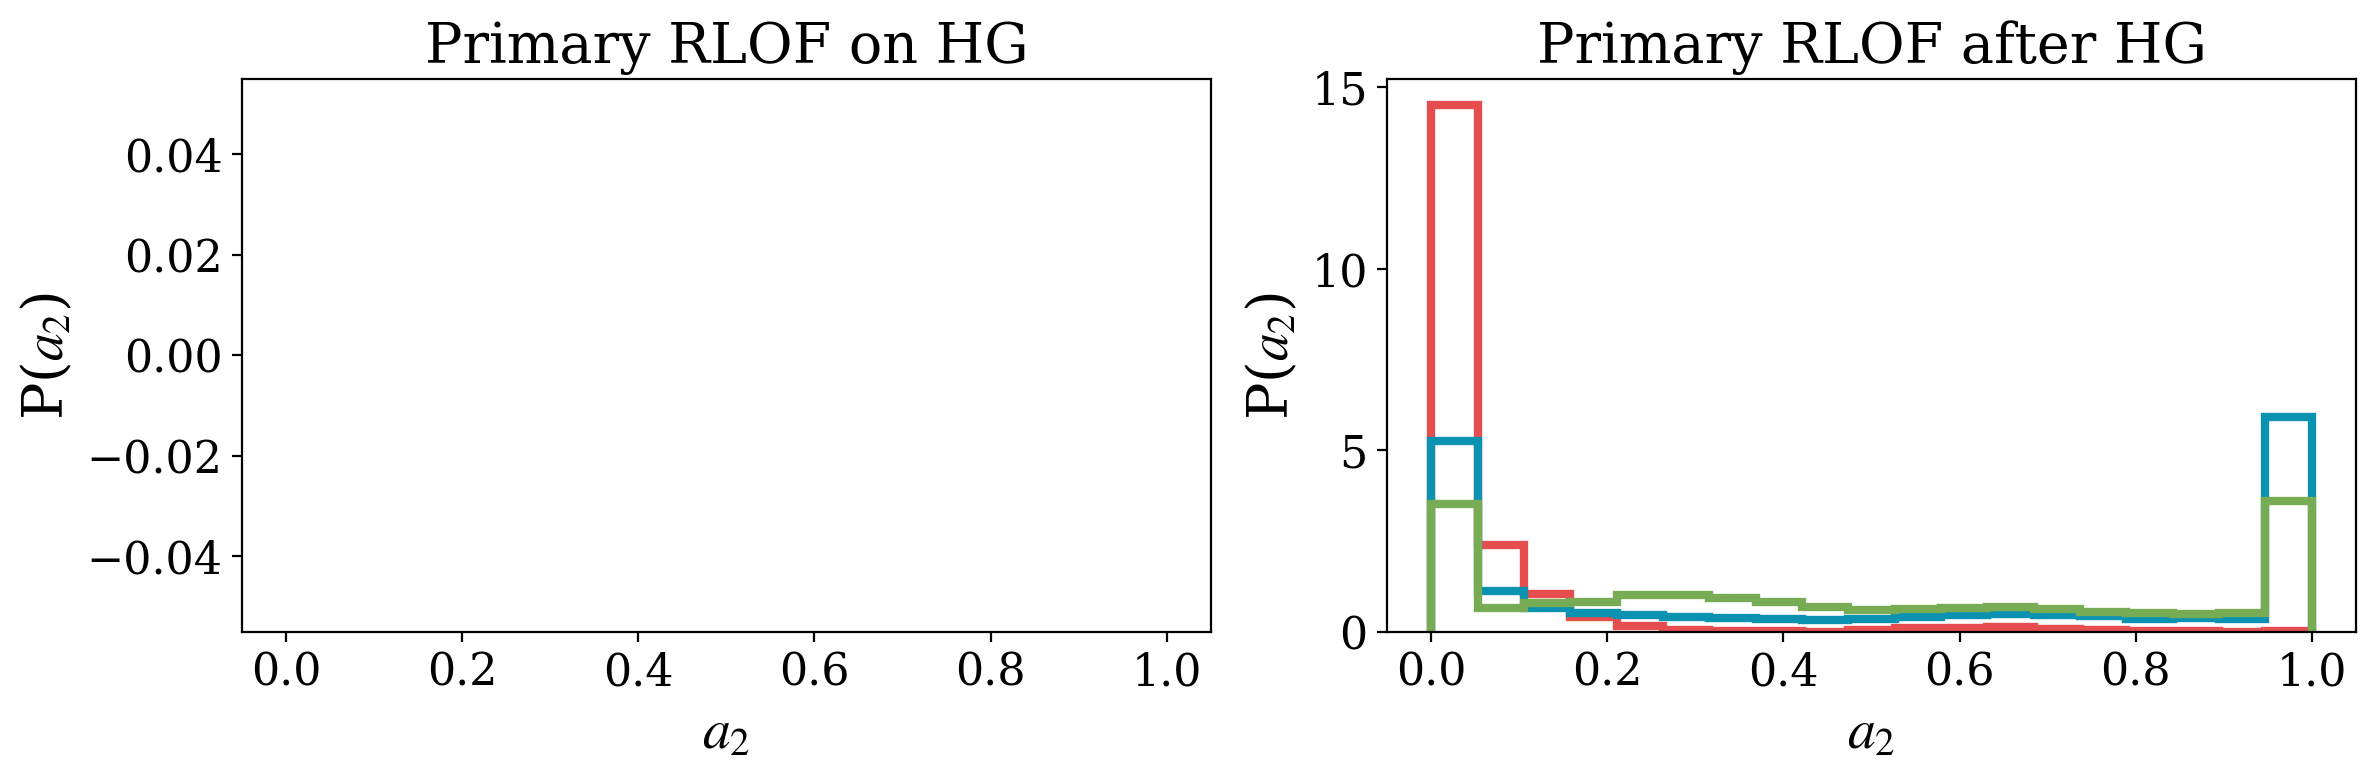

In [14]:
fig, axes = plt.subplots(ncols=2, figsize=(12,4))
for pop_name in pop_names:
    pop_df = pop_spin_dfs[pop_name][pop_spin_dfs[pop_name]['BBH'] & pop_spin_dfs[pop_name]['Merges_Hubble_Time']]
    
    rlof_primary_mask = (pop_df['RLOF_Primary'] == True)

    rlof_hg_mask = pop_df['MT_Donor_Hist(SN)_Primary'].apply(lambda x: 2 in x if isinstance(x, list) else False)
    # rlof_cheb_mask = pop_df['MT_Donor_Hist(SN)_Primary'].apply(lambda x: 4 in x if isinstance(x, list) else False)

    axes[0].hist(pop_df[(rlof_primary_mask & rlof_hg_mask) ]['a2'], bins=np.linspace(0,1,20), histtype='step', lw=3, density=True, color=pop_colors[pop_name])
    axes[0].set_title('Primary RLOF on HG', fontsize=20)
    axes[0].set_xlabel('$a_2$', fontsize=20)
    axes[0].set_ylabel('P($a_2$)', fontsize=20)

    
    axes[1].hist(pop_df[(rlof_primary_mask & ~rlof_hg_mask)]['a2'], bins=np.linspace(0,1,20), histtype='step', lw=3, density=True, color=pop_colors[pop_name])
    axes[1].set_title('Primary RLOF after HG', fontsize=20)
    axes[1].set_xlabel('$a_2$', fontsize=20)
    axes[1].set_ylabel('P($a_2$)', fontsize=20)

plt.tight_layout()
plt.show()

### Which SMT binaries have lower secondary spin with K26 than perfect tides?


In [15]:
realistic_smt_fb2 = pop_spin_dfs['realistic'][(pop_spin_dfs['realistic']['BBH']) & (pop_spin_dfs['realistic']['Merges_Hubble_Time']) & (pop_spin_dfs['realistic']['RLOF_Primary']) & (~pop_spin_dfs['realistic']['CE_Secondary']) & (pop_spin_dfs['realistic']['fallback_2'] > 0.1) & (pop_spin_dfs['realistic']['a2'] < 0.1)]

notides_smt_fb2 = pop_spin_dfs['notides'][(pop_spin_dfs['notides']['BBH']) & (pop_spin_dfs['notides']['Merges_Hubble_Time']) & (~pop_spin_dfs['notides']['CE_Secondary']) & (pop_spin_dfs['notides']['fallback_2'] > 0.1) & (pop_spin_dfs['notides']['a2'] > 0.4)]
perfect_smt_fb2 = pop_spin_dfs['perfect'][(pop_spin_dfs['perfect']['BBH']) & (pop_spin_dfs['perfect']['Merges_Hubble_Time']) & (~pop_spin_dfs['perfect']['CE_Secondary']) & (pop_spin_dfs['perfect']['fallback_2'] > 0.1) & (pop_spin_dfs['perfect']['a2'] > 0.4)]

notides_realistic = notides_smt_fb2.join(realistic_smt_fb2.set_index('SEED'), on='SEED', lsuffix='_notides', rsuffix='_realistic', how='inner')[['SEED', 'a2_notides', 'chi_eff_notides', 'a2_realistic', 'chi_eff_realistic']]
notides_realistic_perfect = notides_realistic.join(perfect_smt_fb2.set_index('SEED'), on='SEED', lsuffix='', rsuffix='_perfect', how='inner')[['SEED', 'a2_notides', 'chi_eff_notides', 'a2_realistic', 'chi_eff_realistic', 'a2', 'chi_eff']]
notides_realistic_perfect

,SEED,a2_notides,chi_eff_notides,a2_realistic,chi_eff_realistic,a2,chi_eff


### Which CE binaries have zero spin with K26 but spin in NOTIDES?

In [16]:
# perfect_seeds = pop_spin_dfs['perfect']['SEED'][pop_spin_dfs['perfect']['Merges_Hubble_Time'] & pop_spin_dfs['perfect']['BBH'] & (pop_spin_dfs['perfect']['RLOF_Primary'])]
# realistic_seeds = pop_spin_dfs['realistic']['SEED'][pop_spin_dfs['realistic']['Merges_Hubble_Time'] & pop_spin_dfs['realistic']['BBH'] & (pop_spin_dfs['realistic']['RLOF_Primary'])]

# both_seeds_mask = np.isin(perfect_seeds, realistic_seeds)
# a2_realistic = pop_spin_dfs['realistic'][pop_spin_dfs['realistic']['SEED'].isin(perfect_seeds[both_seeds_mask])]['a2'].values
# a2_perfect = pop_spin_dfs['perfect'][pop_spin_dfs['perfect']['SEED'].isin(perfect_seeds[both_seeds_mask])]['a2'].values

# notides_ce_fb2 = pop_spin_dfs['notides'][(pop_spin_dfs['notides']['BBH']) & (pop_spin_dfs['notides']['Merges_Hubble_Time']) & (pop_spin_dfs['notides']['fallback_2'] > 0.1)]
realistic_ce_fb2 = pop_spin_dfs['realistic'][(pop_spin_dfs['realistic']['BBH']) & (pop_spin_dfs['realistic']['Merges_Hubble_Time']) & (pop_spin_dfs['realistic']['CE_Secondary']) & (pop_spin_dfs['realistic']['fallback_2'] > 0.1)]
# perfect_ce_fb2 = pop_spin_dfs['perfect'][(pop_spin_dfs['perfect']['BBH']) & (pop_spin_dfs['perfect']['Merges_Hubble_Time']) & (pop_spin_dfs['perfect']['fallback_2'] > 0.1)]

realistic_ce_fb2

,SEED,Mass@ZAMS(1),Mass@ZAMS(2),Metallicity@ZAMS(1),Omega(1),Omega(2),Eccentricity@ZAMS,SemiMajorAxis@ZAMS,CH_on_MS(1),CH_on_MS(2),Mass@DCO(1),Mass@DCO(2),SemiMajorAxis@DCO,Eccentricity@DCO,Stellar_Type(1),Stellar_Type(2),Merges_Hubble_Time,Time@DCO,Coalescence_Time,M_min@DCO,M_max@DCO,Ang_Momentum(SN)_Primary,Ang_Momentum(SN)_Secondary,Ang_Momentum(SN)_Both,MT_Donor_Hist(SN)_Primary,MT_Donor_Hist(SN)_Secondary,Mass(CP)_Primary,Mass(CP)_Secondary,Mass(CP)_Both,Mass(SN)_Primary,Mass(SN)_Secondary,Mass(SN)_Both,Mass_CO_Core@CO(SN)_Primary,Mass_CO_Core@CO(SN)_Secondary,Mass_CO_Core@CO(SN)_Both,Mass_Core@CO(SN)_Primary,Mass_Core@CO(SN)_Secondary,Mass_Core@CO(SN)_Both,Mass_Total@CO(SN)_Primary,Mass_Total@CO(SN)_Secondary,Mass_Total@CO(SN)_Both,Number_of_RLOF(SN)_Primary,Number_of_RLOF(SN)_Secondary,Number_of_RLOF(SN)_Both,Omega(SN)_Primary,Omega(SN)_Secondary,Omega(SN)_Both,Orbital_Period<SN_Primary,Orbital_Period<SN_Secondary,Orbital_Period<SN_Both,RLOF_Primary,RLOF_Secondary,RLOF_Both,Radius_Core@CO(SN)_Primary,Radius_Core@CO(SN)_Secondary,Radius_Core@CO(SN)_Both,Radius_Total@CO(SN)_Primary,Radius_Total@CO(SN)_Secondary,Radius_Total@CO(SN)_Both,SN_Orbit_Inclination_Angle_Primary,SN_Orbit_Inclination_Angle_Secondary,SN_Orbit_Inclination_Angle_Both,SN_Type(SN)_Primary,SN_Type(SN)_Secondary,SN_Type(SN)_Both,SemiMajorAxis<SN_Primary,SemiMajorAxis<SN_Secondary,SemiMajorAxis<SN_Both,Stellar_Type_Prev(SN)_Primary,Stellar_Type_Prev(SN)_Secondary,Stellar_Type_Prev(SN)_Both,Time@SN_Primary,Time@SN_Secondary,Time@SN_Both,Eccentricity<CE_Primary,Eccentricity<CE_Secondary,Eccentricity<CE_Both,Mass(1)<CE_Primary,Mass(1)<CE_Secondary,Mass(1)<CE_Both,Mass(2)<CE_Primary,Mass(2)<CE_Secondary,Mass(2)<CE_Both,SemiMajorAxis<CE_Primary,SemiMajorAxis<CE_Secondary,SemiMajorAxis<CE_Both,Stellar_Type(1)<CE_Primary,Stellar_Type(1)<CE_Secondary,Stellar_Type(1)<CE_Both,Stellar_Type(1)>CE_Primary,Stellar_Type(1)>CE_Secondary,Stellar_Type(1)>CE_Both,Stellar_Type(2)<CE_Primary,Stellar_Type(2)<CE_Secondary,Stellar_Type(2)<CE_Both,Stellar_Type(2)>CE_Primary,Stellar_Type(2)>CE_Secondary,Stellar_Type(2)>CE_Both,Time@CE_Primary,Time@CE_Secondary,Time@CE_Both,CE_Primary,CE_Secondary,CE_Both,BBH,BHNS,BNS,a1,a2,a1_orb,a2_orb,fallback_1,fallback_2,iota1,iota2,chi_eff,chi_eff_orb
3,268128,39.010147,27.517262,0.000431,0.000000e+00,4.215280,0.103031,7.361368,False,False,14.540433,10.477317,0.073187,0.000000e+00,14,14,True,7.870441,2420.265687,10.477317,14.540433,0.000000e+00,2.379390e-05,NaN,NaN,[4],27.168497,14.540433,NaN,14.540433,10.477317,NaN,10.896358,7.753196,NaN,10.896358,7.753196,NaN,14.540433,10.477317,NaN,0.0,1.0,NaN,0.000000e+00,4.215280,NaN,2275.516426,1.445858,NaN,False,True,True,0.000071,0.000071,NaN,1.223451,1.088017,NaN,0.0,0.0,NaN,1.0,1.0,NaN,11.741693,0.073187,NaN,8.0,8.0,NaN,5.926063,7.870441,NaN,NaN,0.0,NaN,NaN,14.540433,NaN,NaN,26.682713,NaN,NaN,2219.554480,NaN,NaN,14.0,NaN,NaN,14.0,NaN,NaN,4.0,NaN,NaN,7.0,NaN,NaN,7.772374,NaN,False,True,False,True,False,False,0.000000e+00,3.472333e-04,0.000090,0.161544,1.0,1.0,0.0,0.0,1.454197e-04,0.067706
13,268492,28.150668,17.621797,0.000800,1.301329e-02,86263.438397,0.141908,0.517809,False,False,8.531670,8.404588,0.013652,4.440892e-16,14,14,True,12.396362,9.195948,8.404588,8.531670,3.964404e-08,2.513419e-01,NaN,[2],[4],24.345920,8.531670,NaN,8.531670,8.404588,NaN,6.249148,6.151072,NaN,6.249148,6.151072,NaN,8.531670,8.404588,NaN,1.0,1.0,NaN,1.300729e-02,86263.438397,NaN,56.252039,0.141571,NaN,True,True,True,0.000071,0.000071,NaN,1.037738,1.037665,NaN,0.0,0.0,NaN,1.0,1.0,NaN,0.920435,0.013652,NaN,8.0,8.0,NaN,7.809763,12.396362,NaN,NaN,0.0,NaN,NaN,8.531670,NaN,NaN,23.962262,NaN,NaN,202.868848,NaN,NaN,14.0,NaN,NaN,14.0,NaN,NaN,4.0,NaN,NaN,7.0,NaN,NaN,12.033832,NaN,False,True,False,True,False,False,8.725007e-07,1.000000e+00,0.004773,1.000000,1.0,1.0,0.0,0.0,4.962487e-01,0.498653
20,268712,29.665596,24.835320,0.000197,8.456330e-24,6.805601,0.145201,4.035372,False,False,11.321712,10.861494,0.054812,1.110223e-16,14,14,Tru

In [17]:
notides_realistic = notides_ce_fb2.join(realistic_ce_fb2.set_index('SEED'), on='SEED', lsuffix='_notides', rsuffix='_realistic', how='inner')
notides_realistic_perfect = notides_realistic.join(perfect_ce_fb2.set_index('SEED'), on='SEED', lsuffix='', rsuffix='_perfect', how='inner')

notides_realistic_perfect[['SEED', 'chi_eff_notides', 'chi_eff_realistic', 'chi_eff']]

NameError: name 'notides_ce_fb2' is not defined

In [ ]:
p_orbital_sn2 = realistic_ce_fb2[realistic_ce_fb2["SEED"] == 1919508]['Orbital_Period<SN_Secondary'].values
p_orbital_sn2
omega_spin_sn2 = realistic_ce_fb2[realistic_ce_fb2["SEED"] == 1919508]['Omega(SN)_Secondary'].values * u.yr**(-1)
print("Spin period at SN:", (2*np.pi/omega_spin_sn2).to(u.day), "Orbital period at SN:", p_orbital_sn2, "d")

realistic_ce_fb2[realistic_ce_fb2["SEED"] == 1919508]

SEED : 1919508
The Common Envelope of the secondary takes place after ST1=14, and from ST2 = 4 (CHeB) to 7 (HeMS). The orbital period at CE onset is 890 d, and the secondary spin period at CE onset is 3600 d.

Up until CE, Equilibrium tides dominate for the CHeB secondary, and it slowly spins up. However, the star loses its entire convective envelope after Common Envelope, beyond which point it is a stripped HeMS star. Our tidal model is not strong enough to spin this up any further, and the spin is locked into the pre-CE value.
Both NOTIDES and PERFECT assume perfect synchronization with the orbit, which leads to systematic over-predictions for CE events.

### Which CHE binaries are not spinning with NOTIDES but spinning with KAPIL2026?

Orbital_Period<SN_Both_notides	: 0.673657

Orbital_Period<SN_Both_realistic: 0.811088

In [18]:
realistic_che = pop_spin_dfs['realistic'][(pop_spin_dfs['realistic']['BBH']) & (pop_spin_dfs['realistic']['Merges_Hubble_Time']) & (pop_spin_dfs['realistic']['CH_on_MS(1)']) & (pop_spin_dfs['realistic']['chi_eff'] > 0.6)]
notides_che = pop_spin_dfs['notides'][(pop_spin_dfs['notides']['BBH']) & (pop_spin_dfs['notides']['Merges_Hubble_Time']) & (pop_spin_dfs['notides']['CH_on_MS(1)']) & (pop_spin_dfs['notides']['chi_eff'] < 0.3)]
perfect_che = pop_spin_dfs['perfect'][(pop_spin_dfs['perfect']['BBH']) & (pop_spin_dfs['perfect']['Merges_Hubble_Time']) & (pop_spin_dfs['perfect']['CH_on_MS(1)'])]

notides_realistic = notides_che.join(realistic_che.set_index('SEED'), on='SEED', lsuffix='_notides', rsuffix='_realistic', how='inner')[['SEED', 'a1_notides', 'chi_eff_notides', 'a1_realistic', 'chi_eff_realistic']]

notides_realistic.join(perfect_che.set_index('SEED'), on='SEED', lsuffix='', rsuffix='_perfect', how='inner')[['SEED', 'a1_notides', 'chi_eff_notides', 'a1_realistic', 'chi_eff_realistic', 'a1', 'chi_eff']]

,SEED,a1_notides,chi_eff_notides,a1_realistic,chi_eff_realistic,a1,chi_eff
SEED,,,,,,,


In [19]:
pop_df = notides_che[notides_che['SEED'] == 9976 ]
pop_df

,SEED,Mass@ZAMS(1),Mass@ZAMS(2),Metallicity@ZAMS(1),Omega(1),Omega(2),Eccentricity@ZAMS,SemiMajorAxis@ZAMS,CH_on_MS(1),CH_on_MS(2),Mass@DCO(1),Mass@DCO(2),SemiMajorAxis@DCO,Eccentricity@DCO,Stellar_Type(1),Stellar_Type(2),Merges_Hubble_Time,Time@DCO,Coalescence_Time,M_min@DCO,M_max@DCO,Ang_Momentum(SN)_Primary,Ang_Momentum(SN)_Secondary,Ang_Momentum(SN)_Both,MT_Donor_Hist(SN)_Primary,MT_Donor_Hist(SN)_Secondary,Mass(CP)_Primary,Mass(CP)_Secondary,Mass(CP)_Both,Mass(SN)_Primary,Mass(SN)_Secondary,Mass(SN)_Both,Mass_CO_Core@CO(SN)_Primary,Mass_CO_Core@CO(SN)_Secondary,Mass_CO_Core@CO(SN)_Both,Mass_Core@CO(SN)_Primary,Mass_Core@CO(SN)_Secondary,Mass_Core@CO(SN)_Both,Mass_Total@CO(SN)_Primary,Mass_Total@CO(SN)_Secondary,Mass_Total@CO(SN)_Both,Number_of_RLOF(SN)_Primary,Number_of_RLOF(SN)_Secondary,Number_of_RLOF(SN)_Both,Omega(SN)_Primary,Omega(SN)_Secondary,Omega(SN)_Both,Orbital_Period<SN_Primary,Orbital_Period<SN_Secondary,Orbital_Period<SN_Both,RLOF_Primary,RLOF_Secondary,RLOF_Both,Radius_Core@CO(SN)_Primary,Radius_Core@CO(SN)_Secondary,Radius_Core@CO(SN)_Both,Radius_Total@CO(SN)_Primary,Radius_Total@CO(SN)_Secondary,Radius_Total@CO(SN)_Both,SN_Orbit_Inclination_Angle_Primary,SN_Orbit_Inclination_Angle_Secondary,SN_Orbit_Inclination_Angle_Both,SN_Type(SN)_Primary,SN_Type(SN)_Secondary,SN_Type(SN)_Both,SemiMajorAxis<SN_Primary,SemiMajorAxis<SN_Secondary,SemiMajorAxis<SN_Both,Stellar_Type_Prev(SN)_Primary,Stellar_Type_Prev(SN)_Secondary,Stellar_Type_Prev(SN)_Both,Time@SN_Primary,Time@SN_Secondary,Time@SN_Both,Eccentricity<CE_Primary,Eccentricity<CE_Secondary,Eccentricity<CE_Both,Mass(1)<CE_Primary,Mass(1)<CE_Secondary,Mass(1)<CE_Both,Mass(2)<CE_Primary,Mass(2)<CE_Secondary,Mass(2)<CE_Both,SemiMajorAxis<CE_Primary,SemiMajorAxis<CE_Secondary,SemiMajorAxis<CE_Both,Stellar_Type(1)<CE_Primary,Stellar_Type(1)<CE_Secondary,Stellar_Type(1)<CE_Both,Stellar_Type(1)>CE_Primary,Stellar_Type(1)>CE_Secondary,Stellar_Type(1)>CE_Both,Stellar_Type(2)<CE_Primary,Stellar_Type(2)<CE_Secondary,Stellar_Type(2)<CE_Both,Stellar_Type(2)>CE_Primary,Stellar_Type(2)>CE_Secondary,Stellar_Type(2)>CE_Both,Time@CE_Primary,Time@CE_Secondary,Time@CE_Both,CE_Primary,CE_Secondary,CE_Both,BBH,BHNS,BNS,a1,a2,a1_orb,a2_orb,fallback_1,fallback_2,iota1,iota2,chi_eff,chi_eff_orb


In [20]:
pop_df = notides_che[notides_che['SEED'] == 9976]

m3 = pop_df["Mass_Total@CO(SN)_Both"].values * u.M_sun
r3 = pop_df["Radius_Total@CO(SN)_Both"].values * u.R_sun
m3_remnant = pop_df["Mass@DCO(1)"].values * u.M_sun
m3_core = pop_df["Mass_CO_Core@CO(SN)_Both"].values * u.M_sun
r3_core = pop_df["Radius_Core@CO(SN)_Both"].values * u.R_sun
period_orb3 = pop_df["Orbital_Period<SN_Both"].values * u.d
st3 = pop_df['Stellar_Type_Prev(SN)_Both']
omega_orb_3 = (2 * np.pi / period_orb3).to(1/u.yr)
# omega3 = pop_df["Omega(SN)_Both"].values / u.yr
j3 = pop_df['Ang_Momentum(SN)_Both'].values * u.Msun * u.AU**2 / u.yr
m3_shell = m3 - m3_core
I3 = (0.21 * m3_core * (r3_core**2) + 0.1 * m3_shell * (r3**2))
omega3 = (j3 / I3).to(1/u.yr)      

omega_to_use = omega_orb_3

print("Orbital period at SN:", period_orb3, "Spin period at SN:", (2*np.pi/omega3).to(u.day))

m3_shell = m3 - m3_core
j3_core = 0.21 * m3_core * (r3_core**2) * omega_to_use
j3_shell = 0.1 * m3_shell * (r3**2) * omega_to_use

fallback_fraction = np.maximum((m3_remnant - m3_core)/m3_shell, 0)
fallback_fraction = np.nan_to_num(fallback_fraction, nan=0.0, posinf=0.0, neginf=0.0) # For stars with no shell, fallback fraction becomes NaN or inf. If so, ignore the shell angular momentum.
fallback_fraction = np.minimum(fallback_fraction, 1.0) # Cap fallback fraction at 1.0

a = (c.c * (j3_core + (fallback_fraction*j3_shell))/ (c.G * (m3_remnant)**2)).to(u.dimensionless_unscaled)
a

Orbital period at SN: [] d Spin period at SN: [] d


<Quantity []>

In [21]:
(j3_core + (j3_shell)).to(u.Msun * u.AU**2 / u.yr)

<Quantity [] AU2 solMass / yr>

In [22]:
pop_df = realistic_che[realistic_che['SEED'] == 9976]
pop_df

,SEED,Mass@ZAMS(1),Mass@ZAMS(2),Metallicity@ZAMS(1),Omega(1),Omega(2),Eccentricity@ZAMS,SemiMajorAxis@ZAMS,CH_on_MS(1),CH_on_MS(2),Mass@DCO(1),Mass@DCO(2),SemiMajorAxis@DCO,Eccentricity@DCO,Stellar_Type(1),Stellar_Type(2),Merges_Hubble_Time,Time@DCO,Coalescence_Time,M_min@DCO,M_max@DCO,Ang_Momentum(SN)_Primary,Ang_Momentum(SN)_Secondary,Ang_Momentum(SN)_Both,MT_Donor_Hist(SN)_Primary,MT_Donor_Hist(SN)_Secondary,Mass(CP)_Primary,Mass(CP)_Secondary,Mass(CP)_Both,Mass(SN)_Primary,Mass(SN)_Secondary,Mass(SN)_Both,Mass_CO_Core@CO(SN)_Primary,Mass_CO_Core@CO(SN)_Secondary,Mass_CO_Core@CO(SN)_Both,Mass_Core@CO(SN)_Primary,Mass_Core@CO(SN)_Secondary,Mass_Core@CO(SN)_Both,Mass_Total@CO(SN)_Primary,Mass_Total@CO(SN)_Secondary,Mass_Total@CO(SN)_Both,Number_of_RLOF(SN)_Primary,Number_of_RLOF(SN)_Secondary,Number_of_RLOF(SN)_Both,Omega(SN)_Primary,Omega(SN)_Secondary,Omega(SN)_Both,Orbital_Period<SN_Primary,Orbital_Period<SN_Secondary,Orbital_Period<SN_Both,RLOF_Primary,RLOF_Secondary,RLOF_Both,Radius_Core@CO(SN)_Primary,Radius_Core@CO(SN)_Secondary,Radius_Core@CO(SN)_Both,Radius_Total@CO(SN)_Primary,Radius_Total@CO(SN)_Secondary,Radius_Total@CO(SN)_Both,SN_Orbit_Inclination_Angle_Primary,SN_Orbit_Inclination_Angle_Secondary,SN_Orbit_Inclination_Angle_Both,SN_Type(SN)_Primary,SN_Type(SN)_Secondary,SN_Type(SN)_Both,SemiMajorAxis<SN_Primary,SemiMajorAxis<SN_Secondary,SemiMajorAxis<SN_Both,Stellar_Type_Prev(SN)_Primary,Stellar_Type_Prev(SN)_Secondary,Stellar_Type_Prev(SN)_Both,Time@SN_Primary,Time@SN_Secondary,Time@SN_Both,Eccentricity<CE_Primary,Eccentricity<CE_Secondary,Eccentricity<CE_Both,Mass(1)<CE_Primary,Mass(1)<CE_Secondary,Mass(1)<CE_Both,Mass(2)<CE_Primary,Mass(2)<CE_Secondary,Mass(2)<CE_Both,SemiMajorAxis<CE_Primary,SemiMajorAxis<CE_Secondary,SemiMajorAxis<CE_Both,Stellar_Type(1)<CE_Primary,Stellar_Type(1)<CE_Secondary,Stellar_Type(1)<CE_Both,Stellar_Type(1)>CE_Primary,Stellar_Type(1)>CE_Secondary,Stellar_Type(1)>CE_Both,Stellar_Type(2)<CE_Primary,Stellar_Type(2)<CE_Secondary,Stellar_Type(2)<CE_Both,Stellar_Type(2)>CE_Primary,Stellar_Type(2)>CE_Secondary,Stellar_Type(2)>CE_Both,Time@CE_Primary,Time@CE_Secondary,Time@CE_Both,CE_Primary,CE_Secondary,CE_Both,BBH,BHNS,BNS,a1,a2,a1_orb,a2_orb,fallback_1,fallback_2,iota1,iota2,chi_eff,chi_eff_orb
6054,9976,46.620192,46.620192,0.000312,3188.430044,3188.430044,0.0,0.074247,True,True,42.04908,42.04908,0.094365,0.051301,14,14,True,6.722919,169.880448,42.04908,42.04908,1.163417,NaN,1.163417,NaN,NaN,42.04908,NaN,42.04908,42.04908,NaN,42.04908,36.422029,NaN,36.422029,36.422029,NaN,36.422029,44.264638,NaN,44.264638,0.0,NaN,0.0,3188.430044,NaN,3188.430044,1.049976,NaN,1.092878,True,True,True,0.000071,NaN,0.000071,2.28753,NaN,2.28753,0.0,NaN,0.0,8.0,NaN,8.0,0.089347,NaN,0.091765,8.0,NaN,8.0,6.722919,NaN,6.722919,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,True,False,False,0.636961,0.636961,0.126108,0.121157,0.717497,0.717497,0.0,0.0,0.636961,0.123632


In [23]:
pop_df = realistic_che[realistic_che['SEED'] == 9976]

m3 = pop_df["Mass_Total@CO(SN)_Both"].values * u.M_sun
r3 = pop_df["Radius_Total@CO(SN)_Both"].values * u.R_sun
m3_remnant = pop_df["Mass@DCO(1)"].values * u.M_sun
m3_core = pop_df["Mass_CO_Core@CO(SN)_Both"].values * u.M_sun
r3_core = pop_df["Radius_Core@CO(SN)_Both"].values * u.R_sun
period_orb3 = pop_df["Orbital_Period<SN_Both"].values * u.d
st3 = pop_df['Stellar_Type_Prev(SN)_Both']
omega_orb_3 = (2 * np.pi / period_orb3).to(1/u.yr)
# omega3 = pop_df["Omega(SN)_Both"].values / u.yr
j3 = pop_df['Ang_Momentum(SN)_Both'].values * u.Msun * u.AU**2 / u.yr
m3_shell = m3 - m3_core
I3 = (0.21 * m3_core * (r3_core**2) + 0.1 * m3_shell * (r3**2))
omega3 = (j3 / I3).to(1/u.yr)      

print("Orbital period at SN:", period_orb3, "Spin period at SN:", (2*np.pi/omega3).to(u.day))

omega_to_use = omega3

m3_shell = m3 - m3_core
j3_core = 0.21 * m3_core * (r3_core**2) * omega_to_use
j3_shell = 0.1 * m3_shell * (r3**2) * omega_to_use

fallback_fraction = np.maximum((m3_remnant - m3_core)/m3_shell, 0)
fallback_fraction = np.nan_to_num(fallback_fraction, nan=0.0, posinf=0.0, neginf=0.0) # For stars with no shell, fallback fraction becomes NaN or inf. If so, ignore the shell angular momentum.
fallback_fraction = np.minimum(fallback_fraction, 1.0) # Cap fallback fraction at 1.0

a = (c.c * (j3_core + (fallback_fraction*j3_shell))/ (c.G * (m3_remnant)**2)).to(u.dimensionless_unscaled)
a

Orbital period at SN: [1.09287789] d Spin period at SN: [0.17507416] d


<Quantity [0.75630766]>

In [24]:
omega_orb_3, omega3

(<Quantity [2099.89921885] 1 / yr>, <Quantity [13108.35012079] 1 / yr>)

In [25]:
pop_df = perfect_che[perfect_che['SEED'] == 9976]
pop_df

,SEED,Mass@ZAMS(1),Mass@ZAMS(2),Metallicity@ZAMS(1),Omega(1),Omega(2),Eccentricity@ZAMS,SemiMajorAxis@ZAMS,CH_on_MS(1),CH_on_MS(2),Mass@DCO(1),Mass@DCO(2),SemiMajorAxis@DCO,Eccentricity@DCO,Stellar_Type(1),Stellar_Type(2),Merges_Hubble_Time,Time@DCO,Coalescence_Time,M_min@DCO,M_max@DCO,Ang_Momentum(SN)_Primary,Ang_Momentum(SN)_Secondary,Ang_Momentum(SN)_Both,MT_Donor_Hist(SN)_Primary,MT_Donor_Hist(SN)_Secondary,Mass(CP)_Primary,Mass(CP)_Secondary,Mass(CP)_Both,Mass(SN)_Primary,Mass(SN)_Secondary,Mass(SN)_Both,Mass_CO_Core@CO(SN)_Primary,Mass_CO_Core@CO(SN)_Secondary,Mass_CO_Core@CO(SN)_Both,Mass_Core@CO(SN)_Primary,Mass_Core@CO(SN)_Secondary,Mass_Core@CO(SN)_Both,Mass_Total@CO(SN)_Primary,Mass_Total@CO(SN)_Secondary,Mass_Total@CO(SN)_Both,Number_of_RLOF(SN)_Primary,Number_of_RLOF(SN)_Secondary,Number_of_RLOF(SN)_Both,Omega(SN)_Primary,Omega(SN)_Secondary,Omega(SN)_Both,Orbital_Period<SN_Primary,Orbital_Period<SN_Secondary,Orbital_Period<SN_Both,RLOF_Primary,RLOF_Secondary,RLOF_Both,Radius_Core@CO(SN)_Primary,Radius_Core@CO(SN)_Secondary,Radius_Core@CO(SN)_Both,Radius_Total@CO(SN)_Primary,Radius_Total@CO(SN)_Secondary,Radius_Total@CO(SN)_Both,SN_Orbit_Inclination_Angle_Primary,SN_Orbit_Inclination_Angle_Secondary,SN_Orbit_Inclination_Angle_Both,SN_Type(SN)_Primary,SN_Type(SN)_Secondary,SN_Type(SN)_Both,SemiMajorAxis<SN_Primary,SemiMajorAxis<SN_Secondary,SemiMajorAxis<SN_Both,Stellar_Type_Prev(SN)_Primary,Stellar_Type_Prev(SN)_Secondary,Stellar_Type_Prev(SN)_Both,Time@SN_Primary,Time@SN_Secondary,Time@SN_Both,Eccentricity<CE_Primary,Eccentricity<CE_Secondary,Eccentricity<CE_Both,Mass(1)<CE_Primary,Mass(1)<CE_Secondary,Mass(1)<CE_Both,Mass(2)<CE_Primary,Mass(2)<CE_Secondary,Mass(2)<CE_Both,SemiMajorAxis<CE_Primary,SemiMajorAxis<CE_Secondary,SemiMajorAxis<CE_Both,Stellar_Type(1)<CE_Primary,Stellar_Type(1)<CE_Secondary,Stellar_Type(1)<CE_Both,Stellar_Type(1)>CE_Primary,Stellar_Type(1)>CE_Secondary,Stellar_Type(1)>CE_Both,Stellar_Type(2)<CE_Primary,Stellar_Type(2)<CE_Secondary,Stellar_Type(2)<CE_Both,Stellar_Type(2)>CE_Primary,Stellar_Type(2)>CE_Secondary,Stellar_Type(2)>CE_Both,Time@CE_Primary,Time@CE_Secondary,Time@CE_Both,CE_Primary,CE_Secondary,CE_Both,BBH,BHNS,BNS,a1,a2,a1_orb,a2_orb,fallback_1,fallback_2,iota1,iota2,chi_eff,chi_eff_orb
9359,9976,46.620192,46.620192,0.000312,0.000062,0.000062,0.0,0.074247,True,True,42.049135,42.049135,0.095305,0.0,14,14,True,6.722919,178.38747,42.049135,42.049135,1.13371,NaN,1.13371,NaN,NaN,42.049135,NaN,42.049135,42.049135,NaN,42.049135,36.422135,NaN,36.422135,36.422135,NaN,36.422135,44.264758,NaN,44.264758,0.0,NaN,0.0,3107.003666,NaN,3107.003666,1.050577,NaN,1.093505,True,True,True,0.000071,NaN,0.000071,2.287533,NaN,2.287533,0.0,NaN,0.0,8.0,NaN,8.0,0.089381,NaN,0.0918,8.0,NaN,8.0,6.722919,NaN,6.722919,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,False,False,True,False,False,0.636962,0.636962,0.126034,0.121087,0.71749,0.71749,0.0,0.0,0.636962,0.12356


In [26]:
pop_df = perfect_che[perfect_che['SEED'] == 9976]

m3 = pop_df["Mass_Total@CO(SN)_Both"].values * u.M_sun
r3 = pop_df["Radius_Total@CO(SN)_Both"].values * u.R_sun
m3_remnant = pop_df["Mass@DCO(1)"].values * u.M_sun
m3_core = pop_df["Mass_CO_Core@CO(SN)_Both"].values * u.M_sun
r3_core = pop_df["Radius_Core@CO(SN)_Both"].values * u.R_sun
period_orb3 = pop_df["Orbital_Period<SN_Both"].values * u.d
st3 = pop_df['Stellar_Type_Prev(SN)_Both']
omega_orb_3 = (2 * np.pi / period_orb3).to(1/u.yr)
# omega3 = pop_df["Omega(SN)_Both"].values / u.yr
j3 = pop_df['Ang_Momentum(SN)_Both'].values * u.Msun * u.AU**2 / u.yr
m3_shell = m3 - m3_core
I3 = (0.21 * m3_core * (r3_core**2) + 0.1 * m3_shell * (r3**2))
omega3 = (j3 / I3).to(1/u.yr)      

omega_to_use =  2 * np.pi * omega_orb_3

print("Orbital period at SN:", period_orb3, "Spin period at SN:", (2*np.pi/omega3).to(u.day))

m3_shell = m3 - m3_core
j3_core = 0.21 * m3_core * (r3_core**2) * omega_to_use
j3_shell = 0.1 * m3_shell * (r3**2) * omega_to_use

fallback_fraction = np.maximum((m3_remnant - m3_core)/m3_shell, 0)
fallback_fraction = np.nan_to_num(fallback_fraction, nan=0.0, posinf=0.0, neginf=0.0) # For stars with no shell, fallback fraction becomes NaN or inf. If so, ignore the shell angular momentum.
fallback_fraction = np.minimum(fallback_fraction, 1.0) # Cap fallback fraction at 1.0

a = (c.c * (j3_core + (fallback_fraction*j3_shell))/ (c.G * (m3_remnant)**2)).to(u.dimensionless_unscaled)
a

Orbital period at SN: [1.09350475] d Spin period at SN: [0.17966256] d


<Quantity [0.7608096]>

In [27]:
2 * np.pi * omega_orb_3, omega3

(<Quantity [13186.49237804] 1 / yr>, <Quantity [12773.57665336] 1 / yr>)

### Which CE binaries have spins in NOTIDES and PERFECT, but not K26?

In [28]:
realistic_ce_fb2 = pop_spin_dfs['realistic'][(pop_spin_dfs['realistic']['BBH']) & (pop_spin_dfs['realistic']['Merges_Hubble_Time']) & (pop_spin_dfs['realistic']['CE_Secondary']) & (pop_spin_dfs['realistic']['fallback_2'] > 0.1) & (pop_spin_dfs['realistic']['a2'] < 0.1)]

notides_ce_fb2 = pop_spin_dfs['notides'][(pop_spin_dfs['notides']['BBH']) & (pop_spin_dfs['notides']['Merges_Hubble_Time']) & (pop_spin_dfs['notides']['CE_Secondary']) & (pop_spin_dfs['notides']['fallback_2'] > 0.1) & (pop_spin_dfs['notides']['a2_orb'] > 0.8)]
perfect_ce_fb2 = pop_spin_dfs['perfect'][(pop_spin_dfs['perfect']['BBH']) & (pop_spin_dfs['perfect']['Merges_Hubble_Time']) & (pop_spin_dfs['perfect']['CE_Secondary']) & (pop_spin_dfs['perfect']['fallback_2'] > 0.1) & (pop_spin_dfs['perfect']['a2_orb'] > 0.8)]

notides_realistic = notides_ce_fb2.join(realistic_ce_fb2.set_index('SEED'), on='SEED', lsuffix='_notides', rsuffix='_realistic', how='inner')[['SEED', 'a2_notides', 'chi_eff_notides', 'a2_realistic', 'chi_eff_realistic']]
notides_realistic_perfect = notides_realistic.join(perfect_ce_fb2.set_index('SEED'), on='SEED', lsuffix='', rsuffix='_perfect', how='inner')[['SEED', 'a2_notides', 'chi_eff_notides', 'a2_realistic', 'chi_eff_realistic', 'a2_orb', 'chi_eff']]
notides_realistic_perfect

,SEED,a2_notides,chi_eff_notides,a2_realistic,chi_eff_realistic,a2_orb,chi_eff
62,127777,0.000226,0.000134,0.000230,0.000136,1.000000,0.586099
129,359424,0.000906,0.000449,0.015748,0.007808,0.800559,0.393610
452,452635,0.000000,0.000000,0.044850,0.021791,0.971526,0.472491
602,410353,0.000700,0.000428,0.003558,0.002174,1.000000,0.613962
682,330730,0.000447,0.000272,0.000447,0.000272,0.860869,0.523231
...,...,...,...,...,...,...,...
139894,1382860,0.000338,0.000174,0.076349,0.039308,1.000000,0.514079
139941,1128035,0.000000,0.000000,0.012041,0.005103,0.995468,0.422073
139944,1128114,0.000000,0.000000,0.061936,0.021379,0.963693,0.334645
140034,1008448,0.000030,0.000012,0.000410,0.000168,1.000000,0.409169


In [29]:
realistic_ce_fb2 = pop_spin_dfs['realistic'][(pop_spin_dfs['realistic']['BBH']) & (pop_spin_dfs['realistic']['Merges_Hubble_Time']) & (pop_spin_dfs['realistic']['CE_Secondary']) & (pop_spin_dfs['realistic']['fallback_2'] > 0.1) & (pop_spin_dfs['realistic']['a1'] >0.99)]
realistic_ce_fb2[['SEED', 'Time@SN_Primary', 'Time@CE_Secondary', 'Time@DCO', 'fallback_2', 'a1', 'chi_eff']]

,SEED,Time@SN_Primary,Time@CE_Secondary,Time@DCO,fallback_2,a1,chi_eff
2333,196867,5.671229,5.433907,5.833567,1.0,1.0,1.0
17030,52979,5.530942,5.251973,5.698577,1.0,1.0,1.0
73823,3192118,5.733002,5.564406,5.965056,1.0,1.0,1.0
82206,2533921,5.780811,5.551742,5.927628,1.0,1.0,1.0
113566,921466,7.797836,7.034936,7.805339,1.0,1.0,1.0
131412,1255869,5.827368,5.620206,5.965081,1.0,1.0,1.0
140112,1409987,5.844457,5.301368,5.844897,1.0,1.0,1.0


In [30]:
realistic_ce_fb2 = pop_spin_dfs['realistic'][(pop_spin_dfs['realistic']['BBH']) & (pop_spin_dfs['realistic']['Merges_Hubble_Time']) & (pop_spin_dfs['realistic']['CE_Secondary']) & (pop_spin_dfs['realistic']['fallback_2'] > 0.1) & (pop_spin_dfs['realistic']['a2'] > 0.8)]

notides_ce_fb2 = pop_spin_dfs['notides'][(pop_spin_dfs['notides']['BBH']) & (pop_spin_dfs['notides']['Merges_Hubble_Time']) & (pop_spin_dfs['notides']['CE_Secondary']) & (pop_spin_dfs['notides']['fallback_2'] > 0.1) & (pop_spin_dfs['notides']['a2'] > 0.8)]
perfect_ce_fb2 = pop_spin_dfs['perfect'][(pop_spin_dfs['perfect']['BBH']) & (pop_spin_dfs['perfect']['Merges_Hubble_Time']) & (pop_spin_dfs['perfect']['CE_Secondary']) & (pop_spin_dfs['perfect']['fallback_2'] > 0.1) & (pop_spin_dfs['perfect']['a2'] > 0.8)]

notides_realistic = notides_ce_fb2.join(realistic_ce_fb2.set_index('SEED'), on='SEED', lsuffix='_notides', rsuffix='_realistic', how='inner')[['SEED', 'a2_notides', 'chi_eff_notides', 'a2_realistic', 'chi_eff_realistic']]
notides_realistic_perfect = notides_realistic.join(perfect_ce_fb2.set_index('SEED'), on='SEED', lsuffix='', rsuffix='_perfect', how='inner')[['SEED', 'a2_notides', 'chi_eff_notides', 'a2_realistic', 'chi_eff_realistic', 'a2', 'chi_eff']]
notides_realistic_perfect

,SEED,a2_notides,chi_eff_notides,a2_realistic,chi_eff_realistic,a2,chi_eff
103130,3063379,1.0,0.643636,1.0,0.647267,1.0,0.65288


In [31]:
notides_ce_fb2 = pop_spin_dfs['notides'][(pop_spin_dfs['notides']['BBH']) & (pop_spin_dfs['notides']['Merges_Hubble_Time']) & (pop_spin_dfs['notides']['CE_Secondary']) & (pop_spin_dfs['notides']['fallback_2'] > 0.1) & (pop_spin_dfs['notides']['a2'] > 0.8)]
perfect_ce_fb2 = pop_spin_dfs['perfect'][(pop_spin_dfs['perfect']['BBH']) & (pop_spin_dfs['perfect']['Merges_Hubble_Time']) & (pop_spin_dfs['perfect']['CE_Secondary']) & (pop_spin_dfs['perfect']['fallback_2'] > 0.1) & (pop_spin_dfs['perfect']['a2'] > 0.8)]

seeds_in_both = np.intersect1d(notides_ce_fb2['SEED'], perfect_ce_fb2['SEED'])


In [32]:
notides_ce_fb2[notides_ce_fb2['SEED'].isin(seeds_in_both)].sort_values('SEED')

,SEED,Mass@ZAMS(1),Mass@ZAMS(2),Metallicity@ZAMS(1),Omega(1),Omega(2),Eccentricity@ZAMS,SemiMajorAxis@ZAMS,CH_on_MS(1),CH_on_MS(2),Mass@DCO(1),Mass@DCO(2),SemiMajorAxis@DCO,Eccentricity@DCO,Stellar_Type(1),Stellar_Type(2),Merges_Hubble_Time,Time@DCO,Coalescence_Time,M_min@DCO,M_max@DCO,Ang_Momentum(SN)_Primary,Ang_Momentum(SN)_Secondary,Ang_Momentum(SN)_Both,MT_Donor_Hist(SN)_Primary,MT_Donor_Hist(SN)_Secondary,Mass(CP)_Primary,Mass(CP)_Secondary,Mass(CP)_Both,Mass(SN)_Primary,Mass(SN)_Secondary,Mass(SN)_Both,Mass_CO_Core@CO(SN)_Primary,Mass_CO_Core@CO(SN)_Secondary,Mass_CO_Core@CO(SN)_Both,Mass_Core@CO(SN)_Primary,Mass_Core@CO(SN)_Secondary,Mass_Core@CO(SN)_Both,Mass_Total@CO(SN)_Primary,Mass_Total@CO(SN)_Secondary,Mass_Total@CO(SN)_Both,Number_of_RLOF(SN)_Primary,Number_of_RLOF(SN)_Secondary,Number_of_RLOF(SN)_Both,Omega(SN)_Primary,Omega(SN)_Secondary,Omega(SN)_Both,Orbital_Period<SN_Primary,Orbital_Period<SN_Secondary,Orbital_Period<SN_Both,RLOF_Primary,RLOF_Secondary,RLOF_Both,Radius_Core@CO(SN)_Primary,Radius_Core@CO(SN)_Secondary,Radius_Core@CO(SN)_Both,Radius_Total@CO(SN)_Primary,Radius_Total@CO(SN)_Secondary,Radius_Total@CO(SN)_Both,SN_Orbit_Inclination_Angle_Primary,SN_Orbit_Inclination_Angle_Secondary,SN_Orbit_Inclination_Angle_Both,SN_Type(SN)_Primary,SN_Type(SN)_Secondary,SN_Type(SN)_Both,SemiMajorAxis<SN_Primary,SemiMajorAxis<SN_Secondary,SemiMajorAxis<SN_Both,Stellar_Type_Prev(SN)_Primary,Stellar_Type_Prev(SN)_Secondary,Stellar_Type_Prev(SN)_Both,Time@SN_Primary,Time@SN_Secondary,Time@SN_Both,Eccentricity<CE_Primary,Eccentricity<CE_Secondary,Eccentricity<CE_Both,Mass(1)<CE_Primary,Mass(1)<CE_Secondary,Mass(1)<CE_Both,Mass(2)<CE_Primary,Mass(2)<CE_Secondary,Mass(2)<CE_Both,SemiMajorAxis<CE_Primary,SemiMajorAxis<CE_Secondary,SemiMajorAxis<CE_Both,Stellar_Type(1)<CE_Primary,Stellar_Type(1)<CE_Secondary,Stellar_Type(1)<CE_Both,Stellar_Type(1)>CE_Primary,Stellar_Type(1)>CE_Secondary,Stellar_Type(1)>CE_Both,Stellar_Type(2)<CE_Primary,Stellar_Type(2)<CE_Secondary,Stellar_Type(2)<CE_Both,Stellar_Type(2)>CE_Primary,Stellar_Type(2)>CE_Secondary,Stellar_Type(2)>CE_Both,Time@CE_Primary,Time@CE_Secondary,Time@CE_Both,CE_Primary,CE_Secondary,CE_Both,BBH,BHNS,BNS,a1,a2,a1_orb,a2_orb,fallback_1,fallback_2,iota1,iota2,chi_eff,chi_eff_orb
103130,3063379,23.804982,23.116112,0.001787,0.0,274397.949668,0.043309,0.904784,False,False,5.440103,9.825474,0.012073,2.288783e-16,14,14,True,9.496043,8.37135,5.440103,9.825474,0.0,1.27741,NaN,"[4, 8]",[4],9.881976,5.440103,NaN,5.440103,9.825474,NaN,5.440103,7.253056,NaN,5.440103,7.253056,NaN,5.440103,9.825474,NaN,2.0,1.0,NaN,0.0,274397.949668,NaN,0.120541,0.124013,NaN,True,True,True,0.000014,0.000071,NaN,0.000014,1.064678,NaN,0.0,0.0,NaN,16.0,1.0,NaN,0.011861,0.012073,NaN,8.0,8.0,NaN,9.178289,9.496043,NaN,NaN,0.0,NaN,NaN,7.509475,NaN,NaN,22.921577,NaN,NaN,666.075203,NaN,NaN,7.0,NaN,NaN,7.0,NaN,NaN,4.0,NaN,NaN,7.0,NaN,NaN,9.070324,NaN,False,True,False,True,False,False,0.0,1.0,5.196354e-09,1.0,0.0,1.0,0.0,0.0,0.643636,0.643636


# $\chi_{\rm eff}$ Plots

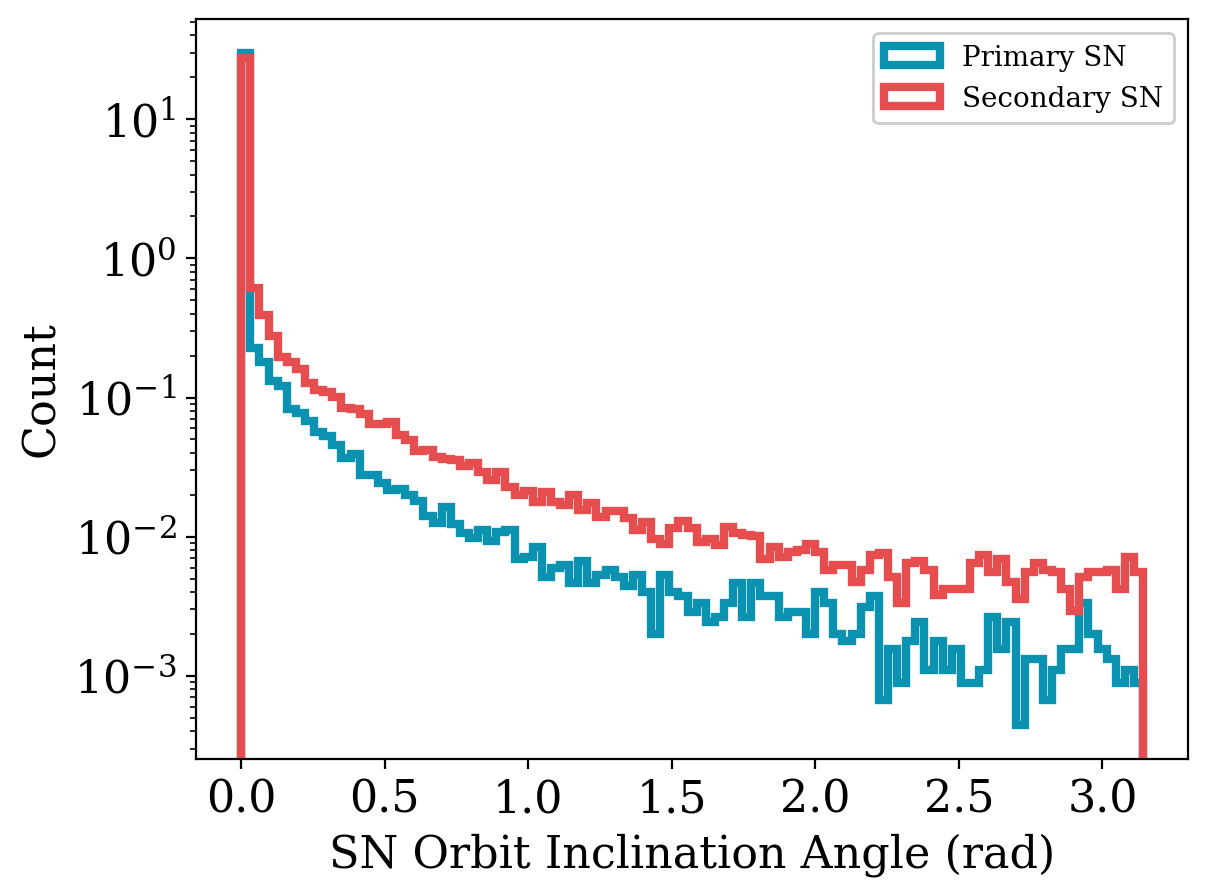

In [33]:
bins = np.linspace(0, np.pi, 100)
plt.hist(pop_spin_dfs['realistic']['SN_Orbit_Inclination_Angle_Primary'], bins=bins, histtype='step', density=True, lw=3, label='Primary SN', color=colorPalette['blue'])
plt.hist(pop_spin_dfs['realistic']['SN_Orbit_Inclination_Angle_Secondary'], bins=bins, histtype='step', density=True, lw=3, label='Secondary SN', color=colorPalette['red'])
plt.xlabel('SN Orbit Inclination Angle (rad)')
plt.ylabel('Count')
plt.legend()
plt.semilogy()
plt.show()

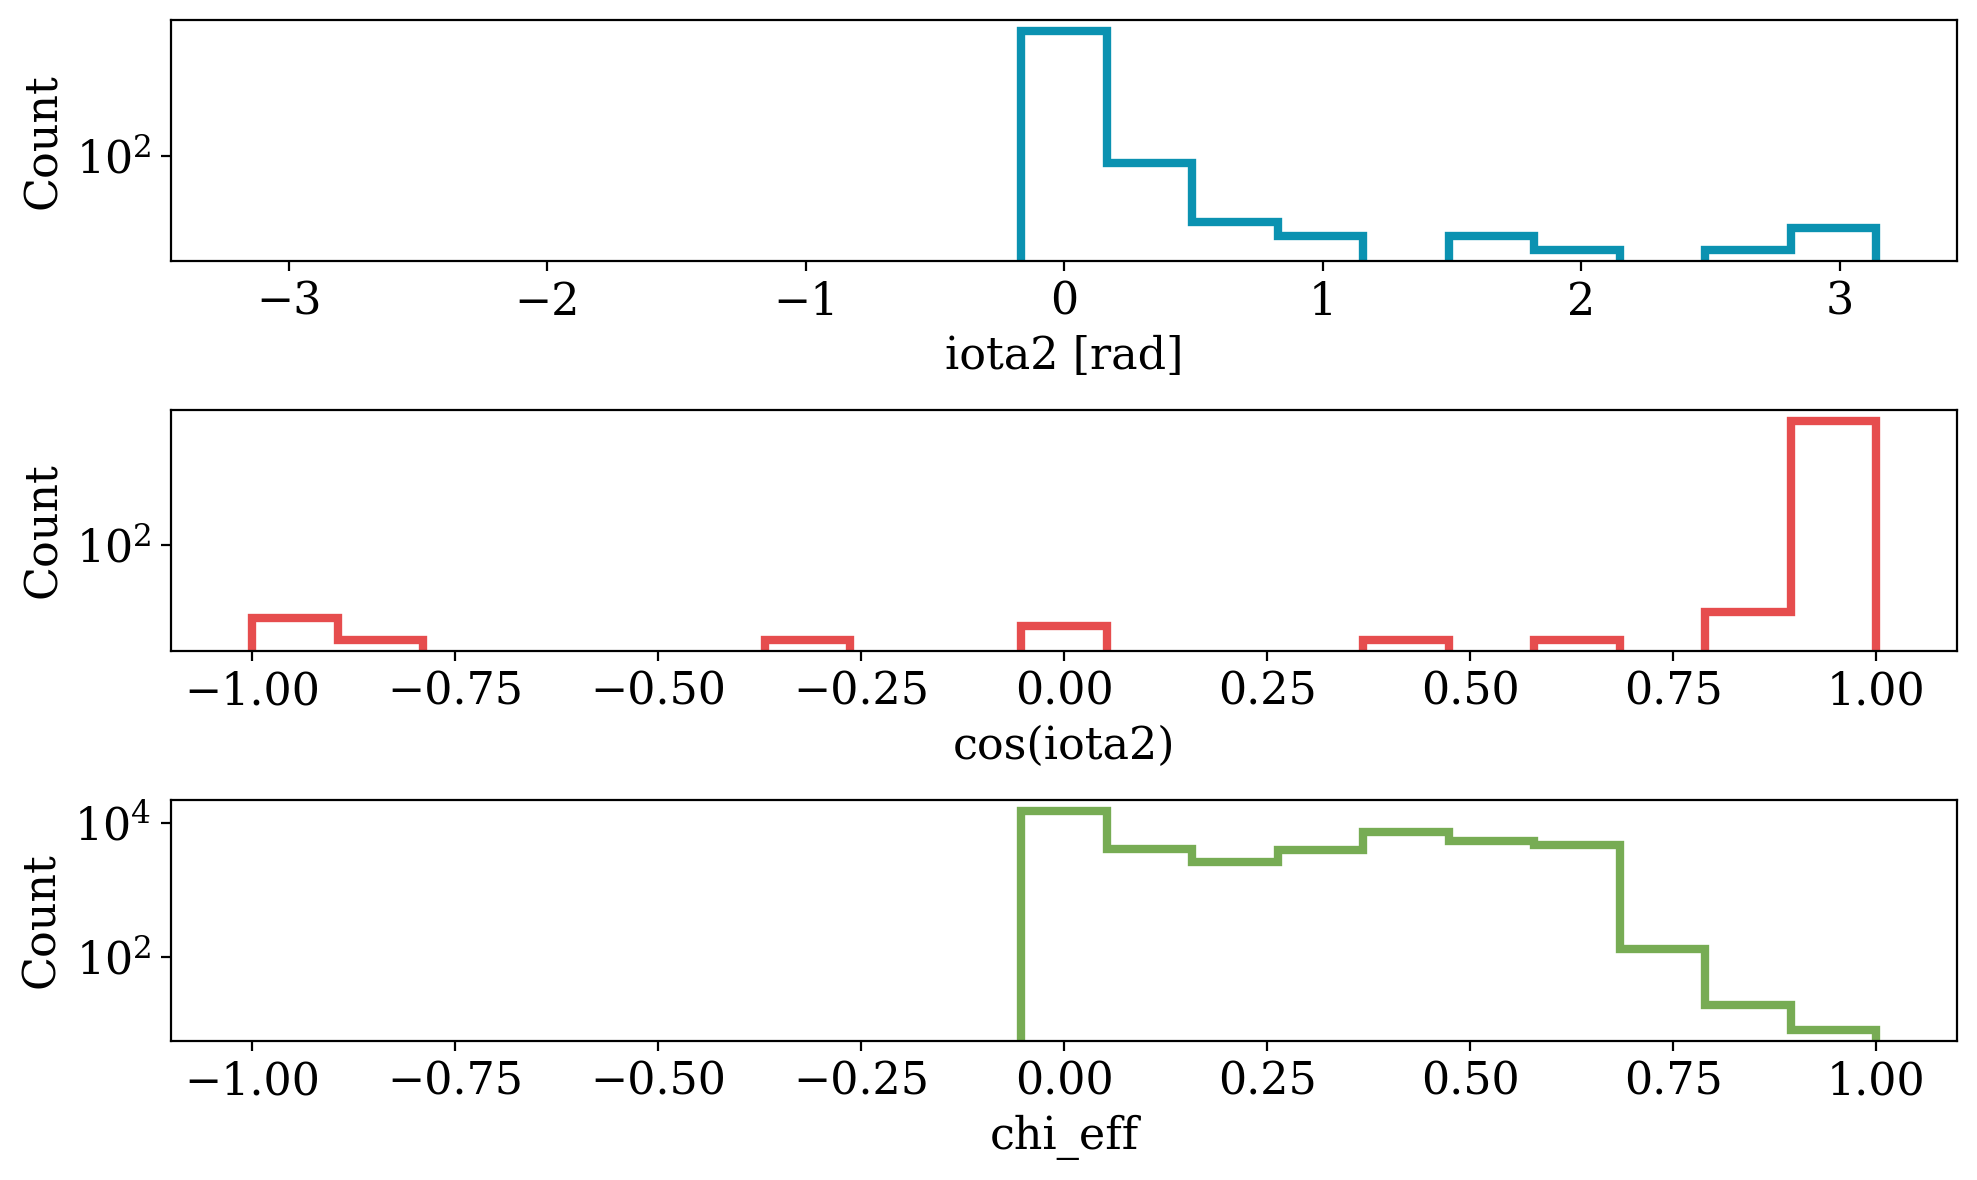

In [34]:
pop_df = pop_spin_dfs['realistic'][(pop_spin_dfs['realistic']['BBH']) & (pop_spin_dfs['realistic']['Merges_Hubble_Time'])]

fig, axes = plt.subplots(ncols=1, nrows=3, figsize=(10,6), sharey=False)
axes[0].hist((pop_df['iota2']), bins=np.linspace(-np.pi, np.pi, 20), histtype='step', lw=3, density=False, color=colorPalette['blue'])
axes[0].set_xlabel('iota2 [rad]')
axes[0].set_ylabel('Count')
axes[0].set_yscale('log')

axes[1].hist(np.cos(pop_df['iota2']), bins=np.linspace(-1, 1, 20), histtype='step', lw=3, density=False, color=colorPalette['red'])
axes[1].set_xlabel('cos(iota2)')
axes[1].set_ylabel('Count')
axes[1].set_yscale('log')

axes[2].hist(pop_df['chi_eff'], bins=np.linspace(-1, 1, 20), histtype='step', lw=3, density=False, color=colorPalette['green'])
axes[2].set_xlabel('chi_eff')
axes[2].set_ylabel('Count')
axes[2].set_yscale('log')

plt.tight_layout()

plt.show()

The inclination angle between the orbits pre- and post- SN give us basically everything we need. We will need to assume the starting orbital spin vectors for both stars, and we choose to believe that, at SN, any given star starts out with its spin aligned to the orbit. For 2 stars, this means the second star would need to rapidly re-orient between the two supernovae.

This may not be super accurate, since both supernova events typically occur within 40 Myr of each other.

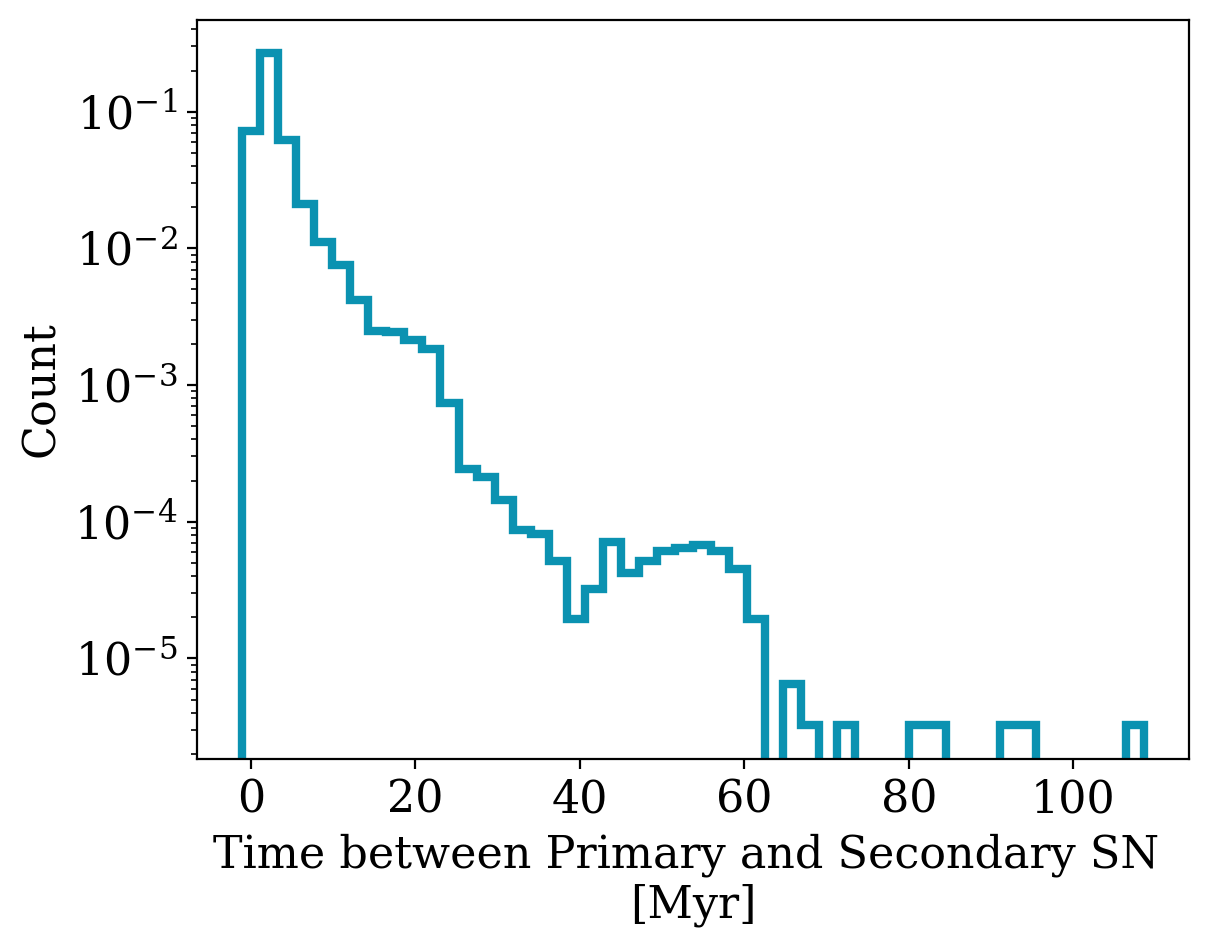

In [35]:
# Distribution of time between supernova events

plt.hist(pop_spin_dfs['realistic']['Time@SN_Secondary'] - pop_spin_dfs['realistic']['Time@SN_Primary'], bins=50, histtype='step', density=True, lw=3, color=colorPalette['blue'])
plt.xlabel('Time between Primary and Secondary SN \n[Myr]')
plt.ylabel('Count')
plt.semilogy()
plt.show()

# Figure 7

In [36]:
def set_up_plot_quantities(pop_df, dco_type=None, mergers=True):
    if dco_type is not None:
        pop_df = pop_df[pop_df[dco_type]]
    
    if mergers:
        pop_df = pop_df[pop_df["Merges_Hubble_Time"]]
        
    m1 = pop_df["Mass@DCO(1)"].values
    m2 = pop_df["Mass@DCO(2)"].values

    a1 = pop_df["a1"].values
    a2 = pop_df["a2"].values

    a1_orb = pop_df["a1_orb"].values
    a2_orb = pop_df["a2_orb"].values

    iota1, iota2, iota2_che = pop_df["SN_Orbit_Inclination_Angle_Primary"], pop_df["SN_Orbit_Inclination_Angle_Secondary"], pop_df["SN_Orbit_Inclination_Angle_Both"]
    iota2 = np.where(np.isnan(iota2), iota2_che, iota2) # If the secondary SN inclination is not recorded, use the "Both" value instead (which should be the same for both SNe)

    # chi_eff = ((m1 * a1) + (m2 * a2)) / (m1 + m2)
    chi_eff_inclination = ((m1 * a1 * np.cos(iota1)) + (m2 * a2 * np.cos(iota2))) / (m1 + m2)

    chi_eff_inclination_orb = ((m1 * a1_orb * np.cos(iota1)) + (m2 * a2_orb * np.cos(iota2))) / (m1 + m2)

    m1_zams = pop_df["Mass@ZAMS(1)"].values
    m2_zams = pop_df["Mass@ZAMS(2)"].values

    period1 = pop_df["Orbital_Period<SN_Primary"]
    period2 = pop_df["Orbital_Period<SN_Secondary"]
    period3 = pop_df["Orbital_Period<SN_Both"]
    period2[np.isnan(period2)] = period3[np.isnan(period2)] # replace the secondary CHE periods with 'both'


    fb1_mask = (pop_df["fallback_1"] < 0.1)
    fb2_mask = (pop_df["fallback_2"] < 0.1)

    ce_2_before_sn1_mask = (pop_df["CE_Secondary"] & (pop_df['Time@CE_Secondary'] < pop_df['Time@SN_Primary']))
    che_mask = pop_df['CH_on_MS(1)']

    any_rlof = (pop_df['RLOF_Primary']==True) + (pop_df['RLOF_Secondary']==True) + (pop_df['RLOF_Both']==True)
    any_ce = (pop_df['CE_Primary']==True) + (pop_df['CE_Secondary']==True) +(pop_df['CE_Both']==True)
    any_che = (pop_df['CH_on_MS(1)']==True) + (pop_df['CH_on_MS(2)']==True)

    any_rlof1 = pop_df["Number_of_RLOF(SN)_Primary"] > 0

    ce_primary_only = (pop_df['CE_Primary']==True) * (pop_df['CE_Secondary']==False) * (pop_df['CE_Both']==False)
    ce_secondary_only = (pop_df['CE_Primary']==False) * (pop_df['CE_Secondary']==True) * (pop_df['CE_Both']==False)
    ce_both = ((pop_df['CE_Primary']==True) * (pop_df['CE_Secondary']==True)) + (pop_df['CE_Both']==True)

    smt = any_rlof * (~any_ce) * (~any_che)
    smt_primary_only = smt * (pop_df['RLOF_Primary']==True) * (pop_df['RLOF_Secondary']==False) * (pop_df['RLOF_Both']==False)
    smt_secondary_only = smt * (pop_df['RLOF_Primary']==False) * (pop_df['RLOF_Secondary']==True) * (pop_df['RLOF_Both']==False)
    smt_both = smt * (((pop_df['RLOF_Primary']==True) * (pop_df['RLOF_Secondary']==True)) + pop_df['RLOF_Both'])

    cheb_rlof2_mask = pop_df["MT_Donor_Hist(SN)_Secondary"].apply(lambda x: 4 in x if isinstance(x, list) else False)
    cheb_rlof1_mask = pop_df["MT_Donor_Hist(SN)_Primary"].apply(lambda x: 4 in x if isinstance(x, list) else False)

    hg_rlof1_mask = pop_df["MT_Donor_Hist(SN)_Primary"].apply(lambda x: 2 in x if isinstance(x, list) else False)
    hg_rlof2_mask = pop_df["MT_Donor_Hist(SN)_Secondary"].apply(lambda x: 2 in x if isinstance(x, list) else False)
        
    ms_rlof1_mask = pop_df["MT_Donor_Hist(SN)_Primary"].apply(lambda x: 1 in x if isinstance(x, list) else False)
    ms_rlof2_mask = pop_df["MT_Donor_Hist(SN)_Secondary"].apply(lambda x: 1 in x if isinstance(x, list) else False)
        
    
    return m1, m2, m1_zams, m2_zams, a1, a2, a1_orb, a2_orb, iota1, iota2, chi_eff_inclination, chi_eff_inclination_orb, period1, period2, fb1_mask, fb2_mask, ce_2_before_sn1_mask, che_mask, any_rlof, any_ce, any_che, any_rlof1, ce_primary_only, ce_secondary_only, ce_both, smt, smt_primary_only, smt_secondary_only, smt_both, cheb_rlof2_mask, cheb_rlof1_mask, hg_rlof1_mask, hg_rlof2_mask, ms_rlof1_mask, ms_rlof2_mask

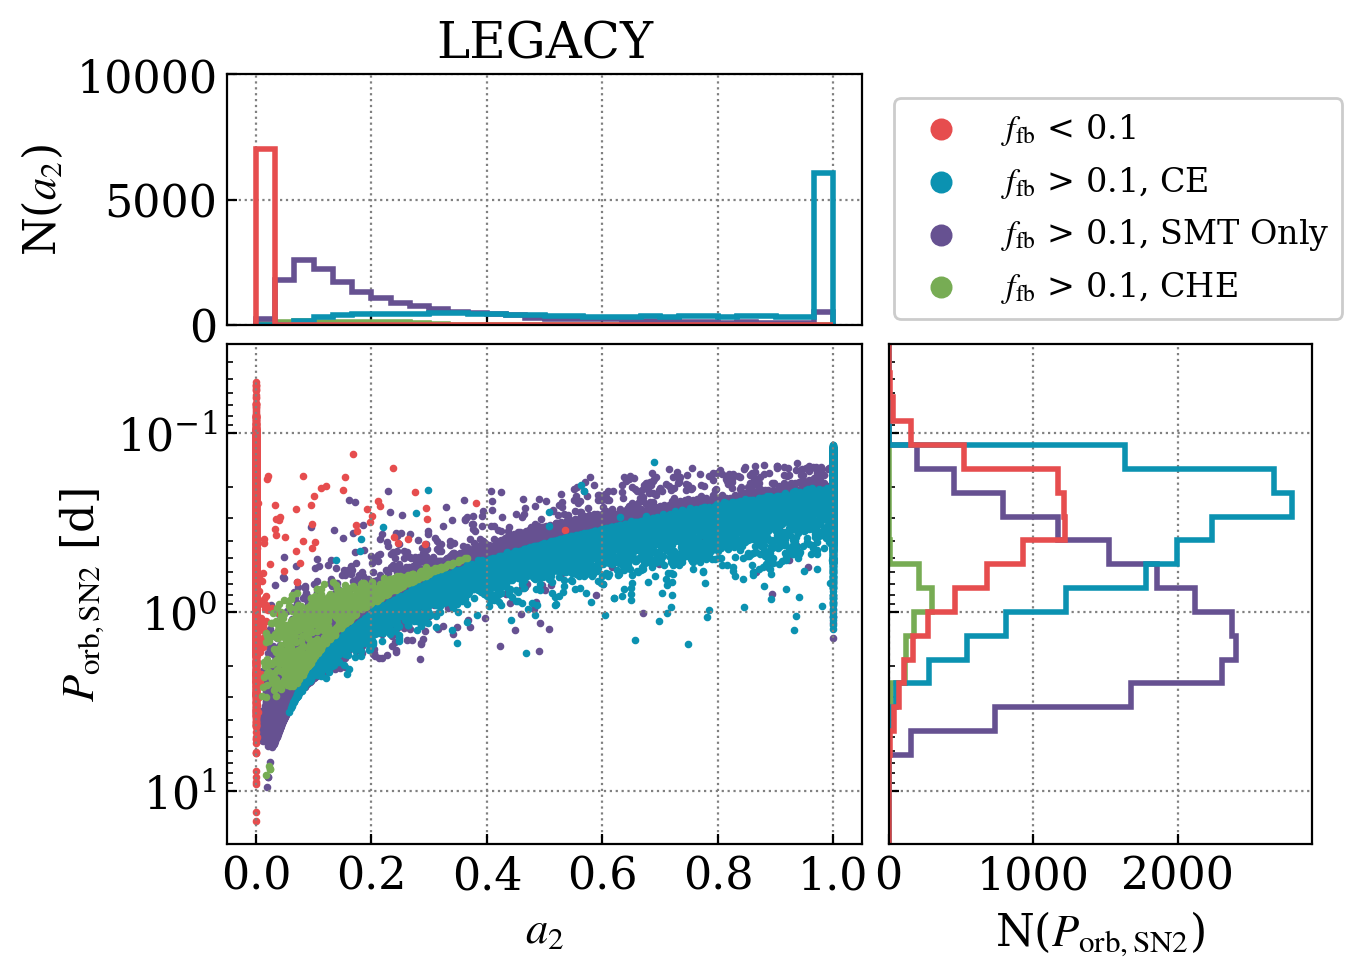

In [37]:
pop_df = pop_spin_dfs['notides']
dco_type='BBH'

m1, m2, m1_zams, m2_zams, a1, a2, a1_orb, a2_orb, iota1, iota2, chi_eff_inclination, chi_eff_inclination_orb, period1, period2, fb1_mask, fb2_mask, ce_2_before_sn1_mask, che_mask, any_rlof, any_ce, any_che, any_rlof1, ce_primary_only, ce_secondary_only, ce_both, smt, smt_primary_only, smt_secondary_only, smt_both, cheb_rlof2_mask, cheb_rlof1_mask, hg_rlof1_mask, hg_rlof2_mask, ms_rlof1_mask, ms_rlof2_mask = set_up_plot_quantities(pop_df, dco_type, mergers=True)

x = a2_orb
y = period2


x_fb_low = x[fb2_mask]
y_fb_low = y[fb2_mask]


x_fb_high_ce = x[~fb2_mask & ~che_mask & ~smt & any_ce]
y_fb_high_ce = y[~fb2_mask & ~che_mask & ~smt & any_ce]

x_fb_high_smt = x[~fb2_mask & ~che_mask & smt]
y_fb_high_smt = y[~fb2_mask & ~che_mask & smt]

x_che = x[~fb2_mask & che_mask]
y_che = y[~fb2_mask & che_mask]


# Set up the figure and axes
fig = plt.figure(figsize=(7, 5))
gs = gridspec.GridSpec(2, 2, width_ratios=[3, 2], height_ratios=[2, 4],
                       wspace=0.05, hspace=0.05)

ax_scatter = fig.add_subplot(gs[1, 0])
ax_hist_x = fig.add_subplot(gs[0, 0], sharex=ax_scatter)
ax_hist_y = fig.add_subplot(gs[1, 1], sharey=ax_scatter)

# Scatter plot
ax_scatter.scatter(x_fb_low, y_fb_low, s=3, c=colorPalette['red'], label=r'$f_{\rm fb}$ < 0.1')
ax_scatter.scatter(x_fb_high_ce, y_fb_high_ce, s=3, c=colorPalette['blue'], label=r'$f_{\rm fb}$ > 0.1, CE')
ax_scatter.scatter(x_fb_high_smt, y_fb_high_smt, s=3, c=colorPalette['violet'], label=r'$f_{\rm fb}$ > 0.1, SMT Only', zorder=0)
ax_scatter.scatter(x_che, y_che, s=3, c=colorPalette['green'], label=r'$f_{\rm fb}$ > 0.1, CHE')

ax_scatter.set_xlabel('$a_2$')
ax_scatter.set_ylabel('$P_{\\rm orb, SN2}$ [d]')
ax_scatter.set_yscale('log')
ax_scatter.legend(loc=(1.05, 1.05), markerscale=4, fontsize=12)
ax_scatter.grid()
ax_scatter.set_xticks(ticks=np.linspace(0, 1, 6))

# Marginal histograms
bin_x = np.linspace(0, 1, 31)
bin_y = np.logspace(-2, 2, 31)

ax_hist_x.hist([x_fb_low, x_fb_high_ce, x_fb_high_smt, x_che], bins=bin_x, stacked=False, histtype='step', lw=2, density=False,
               color=[colorPalette['red'], colorPalette['blue'], colorPalette['violet'], colorPalette['green']])
ax_hist_y.hist([y_fb_low, y_fb_high_ce, y_fb_high_smt, y_che], bins=bin_y, stacked=False, histtype='step', lw=2, density=False, alpha=1.0, orientation='horizontal', 
                color=[colorPalette['red'], colorPalette['blue'], colorPalette['violet'], colorPalette['green']])


ax_hist_x.set_ylabel('N($a_2$)')
ax_hist_y.set_xlabel(r'N($P_{\rm orb, SN2}$)')
# ax_hist_x.set_yscale('log')
# ax_hist_y.set_xscale('log')
ax_hist_x.grid()
ax_hist_y.grid()

ax_scatter.tick_params(direction="in", which='both')
ax_hist_x.tick_params(direction="in", which='both')
ax_hist_y.tick_params(direction="in", which='both')

ax_scatter.set_ylim(10**(-1.5), 10**(1.3))
ax_hist_x.set_ylim(0, 10000)

# Turn off tick labels on histograms
plt.setp(ax_hist_x.get_xticklabels(), visible=False)
plt.setp(ax_hist_y.get_yticklabels(), visible=False)

plt.gca().invert_yaxis()

ax_hist_x.set_title('LEGACY')
plt.savefig(plot_path+'notides_a2_period2_scatter.png', dpi=300, bbox_inches='tight')

plt.show()


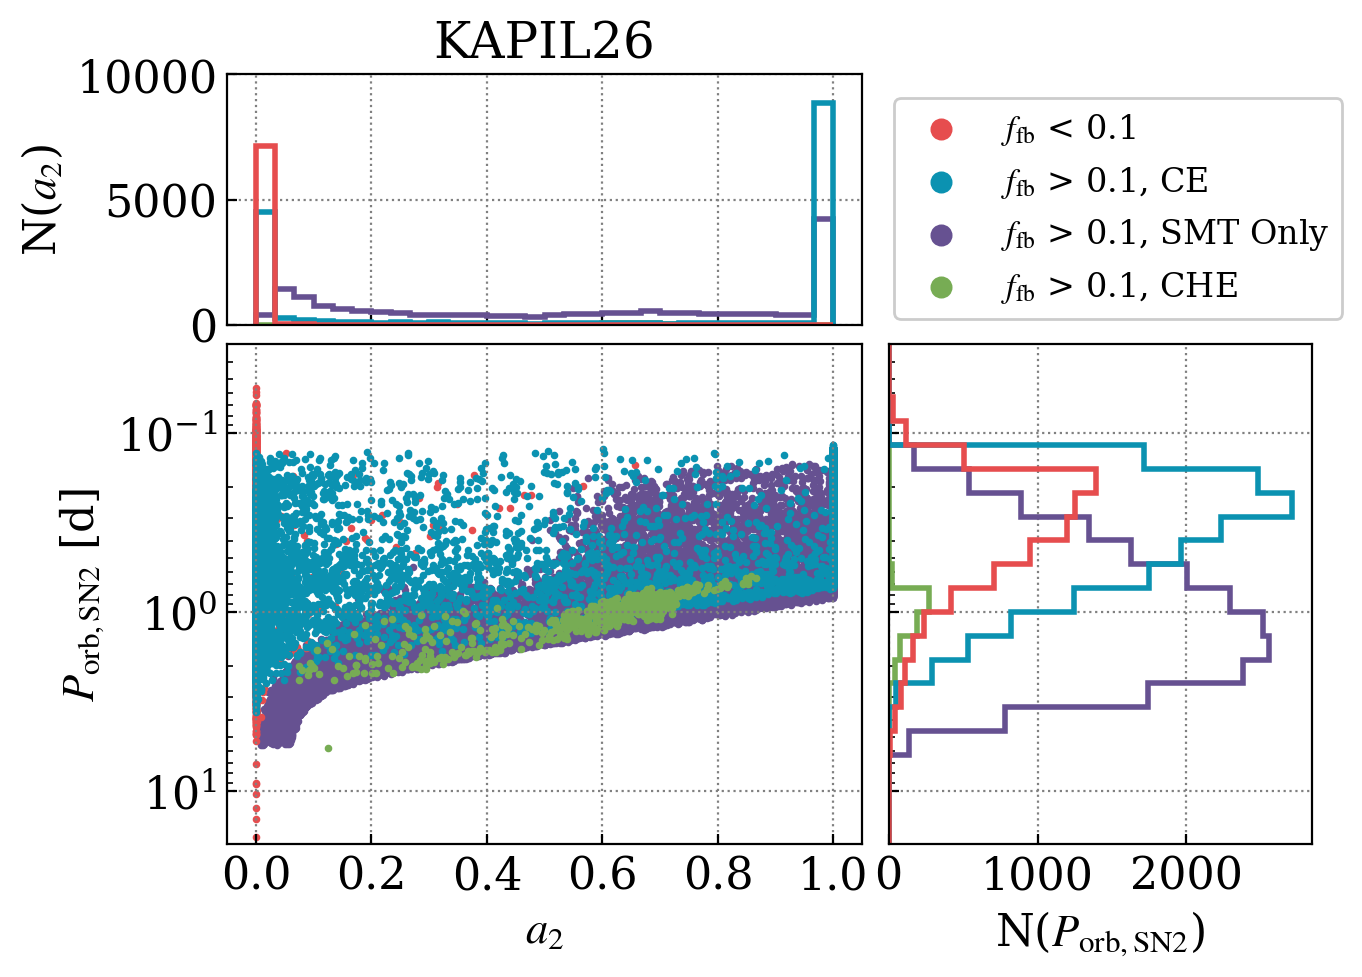

In [38]:
pop_df = pop_spin_dfs['realistic']
dco_type='BBH'

m1, m2, m1_zams, m2_zams, a1, a2, a1_orb, a2_orb, iota1, iota2, chi_eff_inclination, chi_eff_inclination_orb, period1, period2, fb1_mask, fb2_mask, ce_2_before_sn1_mask, che_mask, any_rlof, any_ce, any_che, any_rlof1, ce_primary_only, ce_secondary_only, ce_both, smt, smt_primary_only, smt_secondary_only, smt_both, cheb_rlof2_mask, cheb_rlof1_mask, hg_rlof1_mask, hg_rlof2_mask, ms_rlof1_mask, ms_rlof2_mask = set_up_plot_quantities(pop_df, dco_type, mergers=True)

x = a2
y = period2


x_fb_low = x[fb2_mask]
y_fb_low = y[fb2_mask]


x_fb_high_ce = x[~fb2_mask & ~che_mask & ~smt & any_ce]
y_fb_high_ce = y[~fb2_mask & ~che_mask & ~smt & any_ce]

x_fb_high_smt = x[~fb2_mask & ~che_mask & smt]
y_fb_high_smt = y[~fb2_mask & ~che_mask & smt]

x_che = x[~fb2_mask & che_mask]
y_che = y[~fb2_mask & che_mask]


# Set up the figure and axes
fig = plt.figure(figsize=(7, 5))
gs = gridspec.GridSpec(2, 2, width_ratios=[3, 2], height_ratios=[2, 4],
                       wspace=0.05, hspace=0.05)

ax_scatter = fig.add_subplot(gs[1, 0])
ax_hist_x = fig.add_subplot(gs[0, 0], sharex=ax_scatter)
ax_hist_y = fig.add_subplot(gs[1, 1], sharey=ax_scatter)

# Scatter plot
ax_scatter.scatter(x_fb_low, y_fb_low, s=3, c=colorPalette['red'], label=r'$f_{\rm fb}$ < 0.1')
ax_scatter.scatter(x_fb_high_ce, y_fb_high_ce, s=3, c=colorPalette['blue'], label=r'$f_{\rm fb}$ > 0.1, CE')
ax_scatter.scatter(x_fb_high_smt, y_fb_high_smt, s=3, c=colorPalette['violet'], label=r'$f_{\rm fb}$ > 0.1, SMT Only', zorder=0)
ax_scatter.scatter(x_che, y_che, s=3, c=colorPalette['green'], label=r'$f_{\rm fb}$ > 0.1, CHE')

ax_scatter.set_xlabel('$a_2$')
ax_scatter.set_ylabel('$P_{\\rm orb, SN2}$ [d]')
ax_scatter.set_yscale('log')
ax_scatter.legend(loc=(1.05, 1.05), markerscale=4, fontsize=12)
ax_scatter.grid()
ax_scatter.set_xticks(ticks=np.linspace(0, 1, 6))

# Marginal histograms
bin_x = np.linspace(0, 1, 31)
bin_y = np.logspace(-2, 2, 31)

ax_hist_x.hist([x_fb_low, x_fb_high_ce, x_fb_high_smt, x_che], bins=bin_x, stacked=False, histtype='step', lw=2, density=False,
               color=[colorPalette['red'], colorPalette['blue'], colorPalette['violet'], colorPalette['green']])
ax_hist_y.hist([y_fb_low, y_fb_high_ce, y_fb_high_smt, y_che], bins=bin_y, stacked=False, histtype='step', lw=2, density=False, alpha=1.0, orientation='horizontal', 
                color=[colorPalette['red'], colorPalette['blue'], colorPalette['violet'], colorPalette['green']])


ax_hist_x.set_ylabel('N($a_2$)')
ax_hist_y.set_xlabel(r'N($P_{\rm orb, SN2}$)')
# ax_hist_x.set_yscale('log')
# ax_hist_y.set_xscale('log')
ax_hist_x.grid()
ax_hist_y.grid()

ax_scatter.tick_params(direction="in", which='both')
ax_hist_x.tick_params(direction="in", which='both')
ax_hist_y.tick_params(direction="in", which='both')

ax_scatter.set_ylim(10**(-1.5), 10**(1.3))
ax_hist_x.set_ylim(0, 10000)

# Turn off tick labels on histograms
plt.setp(ax_hist_x.get_xticklabels(), visible=False)
plt.setp(ax_hist_y.get_yticklabels(), visible=False)

plt.gca().invert_yaxis()

ax_hist_x.set_title('KAPIL26')
plt.savefig(plot_path+'realistic_a2_period2_scatter.png', dpi=300, bbox_inches='tight')

plt.show()


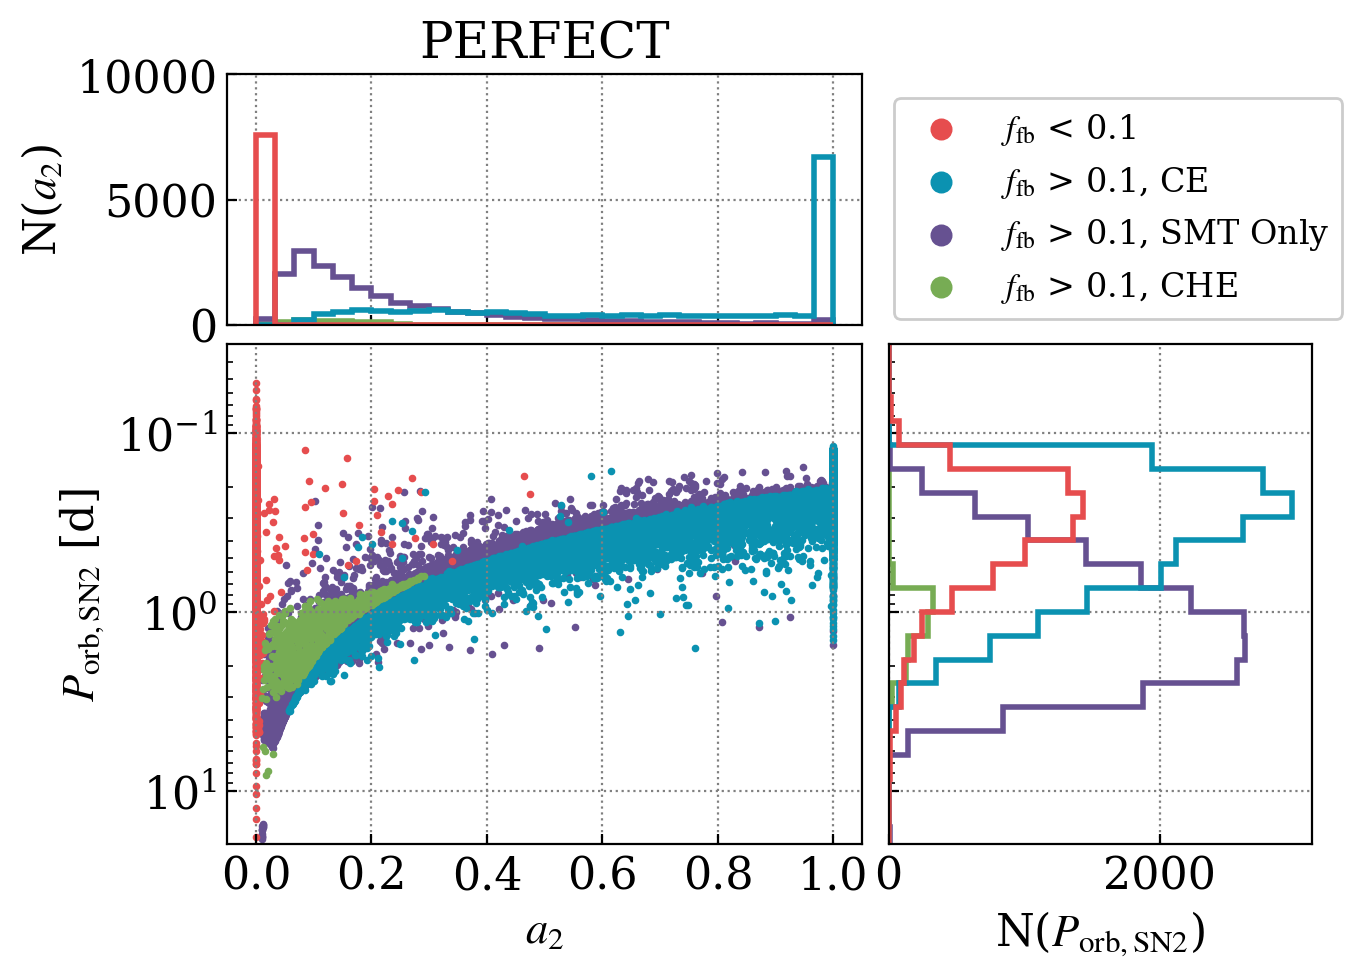

In [39]:
pop_df = pop_spin_dfs['perfect']
dco_type='BBH'

m1, m2, m1_zams, m2_zams, a1, a2, a1_orb, a2_orb, iota1, iota2, chi_eff_inclination, chi_eff_inclination_orb, period1, period2, fb1_mask, fb2_mask, ce_2_before_sn1_mask, che_mask, any_rlof, any_ce, any_che, any_rlof1, ce_primary_only, ce_secondary_only, ce_both, smt, smt_primary_only, smt_secondary_only, smt_both, cheb_rlof2_mask, cheb_rlof1_mask, hg_rlof1_mask, hg_rlof2_mask, ms_rlof1_mask, ms_rlof2_mask = set_up_plot_quantities(pop_df, dco_type, mergers=True)

x = a2_orb
y = period2


x_fb_low = x[fb2_mask]
y_fb_low = y[fb2_mask]


x_fb_high_ce = x[~fb2_mask & ~che_mask & ~smt & any_ce]
y_fb_high_ce = y[~fb2_mask & ~che_mask & ~smt & any_ce]

x_fb_high_smt = x[~fb2_mask & ~che_mask & smt]
y_fb_high_smt = y[~fb2_mask & ~che_mask & smt]

x_che = x[~fb2_mask & che_mask]
y_che = y[~fb2_mask & che_mask]


# Set up the figure and axes
fig = plt.figure(figsize=(7, 5))
gs = gridspec.GridSpec(2, 2, width_ratios=[3, 2], height_ratios=[2, 4],
                       wspace=0.05, hspace=0.05)

ax_scatter = fig.add_subplot(gs[1, 0])
ax_hist_x = fig.add_subplot(gs[0, 0], sharex=ax_scatter)
ax_hist_y = fig.add_subplot(gs[1, 1], sharey=ax_scatter)

# Scatter plot
ax_scatter.scatter(x_fb_low, y_fb_low, s=3, c=colorPalette['red'], label=r'$f_{\rm fb}$ < 0.1')
ax_scatter.scatter(x_fb_high_ce, y_fb_high_ce, s=3, c=colorPalette['blue'], label=r'$f_{\rm fb}$ > 0.1, CE')
ax_scatter.scatter(x_fb_high_smt, y_fb_high_smt, s=3, c=colorPalette['violet'], label=r'$f_{\rm fb}$ > 0.1, SMT Only', zorder=0)
ax_scatter.scatter(x_che, y_che, s=3, c=colorPalette['green'], label=r'$f_{\rm fb}$ > 0.1, CHE')

ax_scatter.set_xlabel('$a_2$')
ax_scatter.set_ylabel('$P_{\\rm orb, SN2}$ [d]')
ax_scatter.set_yscale('log')
ax_scatter.legend(loc=(1.05, 1.05), markerscale=4, fontsize=12)
ax_scatter.grid()
ax_scatter.set_xticks(ticks=np.linspace(0, 1, 6))

# Marginal histograms
bin_x = np.linspace(0, 1, 31)
bin_y = np.logspace(-2, 2, 31)

ax_hist_x.hist([x_fb_low, x_fb_high_ce, x_fb_high_smt, x_che], bins=bin_x, stacked=False, histtype='step', lw=2, density=False,
               color=[colorPalette['red'], colorPalette['blue'], colorPalette['violet'], colorPalette['green']])
ax_hist_y.hist([y_fb_low, y_fb_high_ce, y_fb_high_smt, y_che], bins=bin_y, stacked=False, histtype='step', lw=2, density=False, alpha=1.0, orientation='horizontal', 
                color=[colorPalette['red'], colorPalette['blue'], colorPalette['violet'], colorPalette['green']])


ax_hist_x.set_ylabel('N($a_2$)')
ax_hist_y.set_xlabel(r'N($P_{\rm orb, SN2}$)')
# ax_hist_x.set_yscale('log')
# ax_hist_y.set_xscale('log')
ax_hist_x.grid()
ax_hist_y.grid()

ax_scatter.tick_params(direction="in", which='both')
ax_hist_x.tick_params(direction="in", which='both')
ax_hist_y.tick_params(direction="in", which='both')

ax_scatter.set_ylim(10**(-1.5), 10**(1.3))
ax_hist_x.set_ylim(0, 10000)

# Turn off tick labels on histograms
plt.setp(ax_hist_x.get_xticklabels(), visible=False)
plt.setp(ax_hist_y.get_yticklabels(), visible=False)

plt.gca().invert_yaxis()

ax_hist_x.set_title('PERFECT')
plt.savefig(plot_path+'perfect_a2_period2_scatter.png', dpi=300, bbox_inches='tight')

plt.show()


In [40]:
for pop_name in pop_names:
    pop_df = pop_spin_dfs[pop_name]
    dco_type='BBH'

    m1, m2, m1_zams, m2_zams, a1, a2, a1_orb, a2_orb, iota1, iota2, chi_eff_inclination, chi_eff_inclination_orb, period1, period2, fb1_mask, fb2_mask, ce_2_before_sn1_mask, che_mask, any_rlof, any_ce, any_che, any_rlof1, ce_primary_only, ce_secondary_only, ce_both, smt, smt_primary_only, smt_secondary_only, smt_both, cheb_rlof2_mask, cheb_rlof1_mask, hg_rlof1_mask, hg_rlof2_mask, ms_rlof1_mask, ms_rlof2_mask = set_up_plot_quantities(pop_df, dco_type)

    print(pop_labels[pop_name])
    if pop_name == 'notides' or pop_name == 'perfect':
        chi_eff_inclination = chi_eff_inclination_orb
    else:
        chi_eff_inclination = chi_eff_inclination
        
    chi_eff_inclination = chi_eff_inclination[~fb2_mask & ~che_mask & smt]
    a2 = a2[~fb2_mask & ~che_mask & smt]

    print(f"Minimally spinning SMT BH: {np.sum(a2<0.2)} / {len(a2)} ({100 * np.sum(a2<0.2)/len(a2):.2f}%)")
    print(f"Maximally spinning SMT BH: {np.sum(a2>0.75)} / {len(a2)} ({100 * np.sum(a2>0.75)/len(a2):.2f}%)")
    print()

LEGACY
Minimally spinning SMT BH: 17297 / 17783 (97.27%)
Maximally spinning SMT BH: 0 / 17783 (0.00%)

KAPIL26
Minimally spinning SMT BH: 4925 / 18979 (25.95%)
Maximally spinning SMT BH: 6966 / 18979 (36.70%)

PERFECT
Minimally spinning SMT BH: 3909 / 18160 (21.53%)
Maximally spinning SMT BH: 3571 / 18160 (19.66%)



# Figure 10

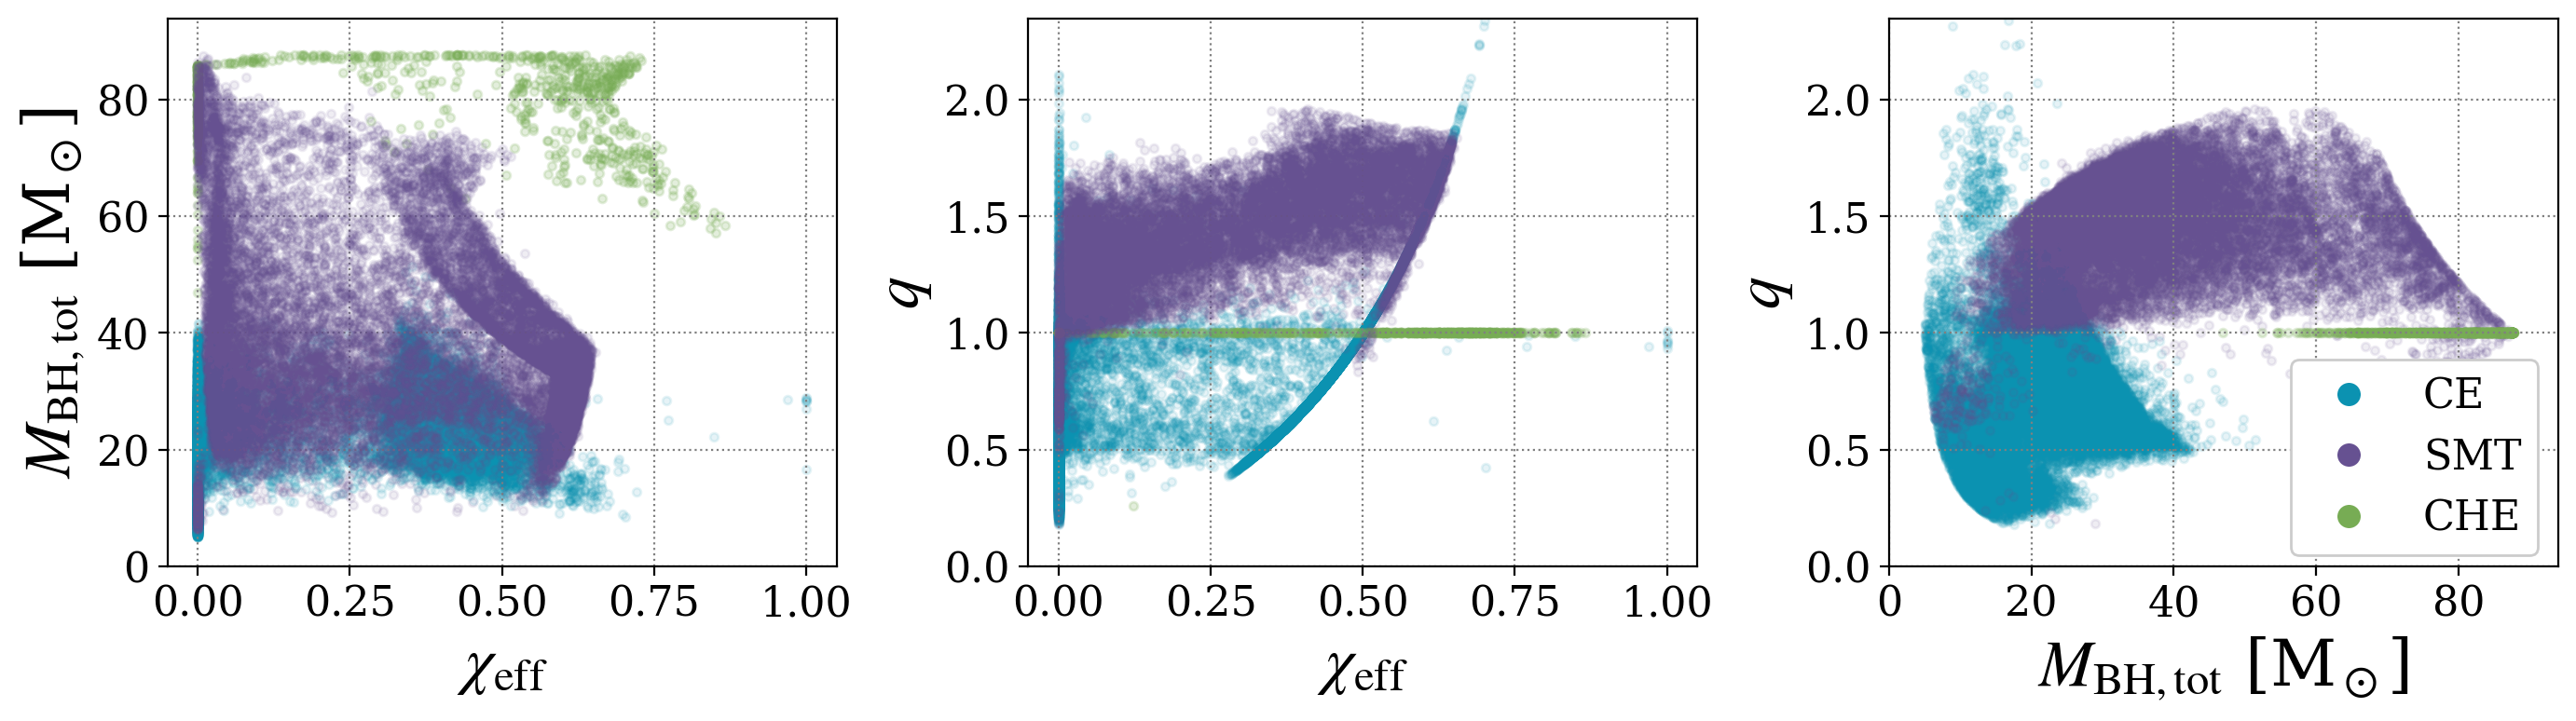

In [41]:
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize



fig, axes = plt.subplots(ncols=3, figsize=(14, 4))

pop_name = 'realistic'
dco_type='BBH'

pop_spin_df = pop_spin_dfs[pop_name]
pop_spin_df = pop_spin_df[(pop_spin_df[dco_type]) & (pop_spin_df["Merges_Hubble_Time"])]
pop_df = pop_spin_df


any_rlof = (pop_df['RLOF_Primary']==True) + (pop_df['RLOF_Secondary']==True) + (pop_df['RLOF_Both']==True)
any_ce = (pop_df['CE_Primary']==True) + (pop_df['CE_Secondary']==True) +(pop_df['CE_Both']==True)
any_che = (pop_df['CH_on_MS(1)']==True) + (pop_df['CH_on_MS(2)']==True)
smt_mask = any_rlof * (~any_ce) * (~any_che)
ce_mask = any_ce * (~any_che)
che_mask = any_che

m1, m2 = pop_df["Mass@DCO(1)"], pop_df["Mass@DCO(2)"]
z1 = pop_df["Metallicity@ZAMS(1)"]
chi_eff_inclination = pop_df['chi_eff']

alpha = 0.1
s = 10

######################################
ax = axes[0]

x_vals = chi_eff_inclination
# y_vals = np.minimum(m1,m2) / np.maximum(m1,m2)
y_vals = m1+m2


ax.scatter(x_vals[ce_mask], y_vals[ce_mask], alpha=alpha, s=s, color=colorPalette['blue'], label='CE', zorder=1)
ax.scatter(x_vals[smt_mask], y_vals[smt_mask], alpha=alpha, s=s, color=colorPalette['violet'], label='SMT', zorder=10)
ax.scatter(x_vals[che_mask], y_vals[che_mask], alpha=2*alpha, s=s, color=colorPalette['green'], label='CHE')

ax.set_xlabel(r'$\chi_{\rm eff}$', fontsize=25)
# ax.set_ylabel(r'$q$', fontsize=25)
ax.set_ylabel('$M_{\\rm BH,tot}$ [M$_\odot$]', fontsize=25)

# ax.set_ylim(0, 1)
ax.set_ylim(0, 94)
ax.set_xlim(-0.05, 1.05)

ax.grid()

############################################

# Get x and y values
# y_vals = np.minimum(m1, m2) / np.maximum(m1, m2)
y_vals = m2/m1
x_vals = chi_eff_inclination


ax = axes[1]
ax.scatter(x_vals[ce_mask], y_vals[ce_mask], alpha=alpha, s=s, color=colorPalette['blue'], label='CE', zorder=1)
ax.scatter(x_vals[smt_mask], y_vals[smt_mask], alpha=alpha, s=s, color=colorPalette['violet'], label='SMT', zorder=10)
ax.scatter(x_vals[che_mask], y_vals[che_mask], alpha=2*alpha, s=s, color=colorPalette['green'], label='CHE')

ax.set_xlabel(r'$\chi_{\rm eff}$', fontsize=25)
ax.set_ylabel(r'$q$', fontsize=25)

ax.set_xlim(-0.05, 1.05)
ax.set_ylim(0, 2.35)
ax.set_yticks([0, 0.5, 1.0, 1.5, 2.0])
ax.grid()

######

ax = axes[2]

# y_vals = np.minimum(m1,m2) / np.maximum(m1,m2)
y_vals = m2/m1
x_vals = m1+m2

ax.scatter(x_vals[ce_mask], y_vals[ce_mask], alpha=alpha, s=s, color=colorPalette['blue'], label='CE', zorder=0)
ax.scatter(x_vals[smt_mask], y_vals[smt_mask], alpha=alpha, s=s, color=colorPalette['violet'], label='SMT', zorder=1)
ax.scatter(x_vals[che_mask], y_vals[che_mask], alpha=2*alpha, s=s, color=colorPalette['green'], label='CHE')

ax.set_xlabel('$M_{\\rm BH,tot}$ [M$_\odot$]', fontsize=25)
ax.set_ylabel(r'$q$', fontsize=25)
ax.set_xlim(0, 94)
ax.set_ylim(0, 2.35)
ax.set_yticks([0, 0.5, 1.0, 1.5, 2.0])

ax.grid()

from matplotlib.lines import Line2D

legend_elements = [
Line2D([0], [0], marker='o', color='w', label='CE',
   markerfacecolor=colorPalette['blue'], markersize=10, alpha=1),
Line2D([0], [0], marker='o', color='w', label='SMT',
       markerfacecolor=colorPalette['violet'], markersize=10, alpha=1),
Line2D([0], [0], marker='o', color='w', label='CHE',
       markerfacecolor=colorPalette['green'], markersize=10, alpha=1),
]

axes[2].legend(handles=legend_elements, fontsize=16, loc=(0.6, 0.02))


plt.tight_layout()
plt.savefig(plot_path+"chi_eff_q_mtot.png", dpi=300, bbox_inches='tight')
plt.show()

## Other correlation plots

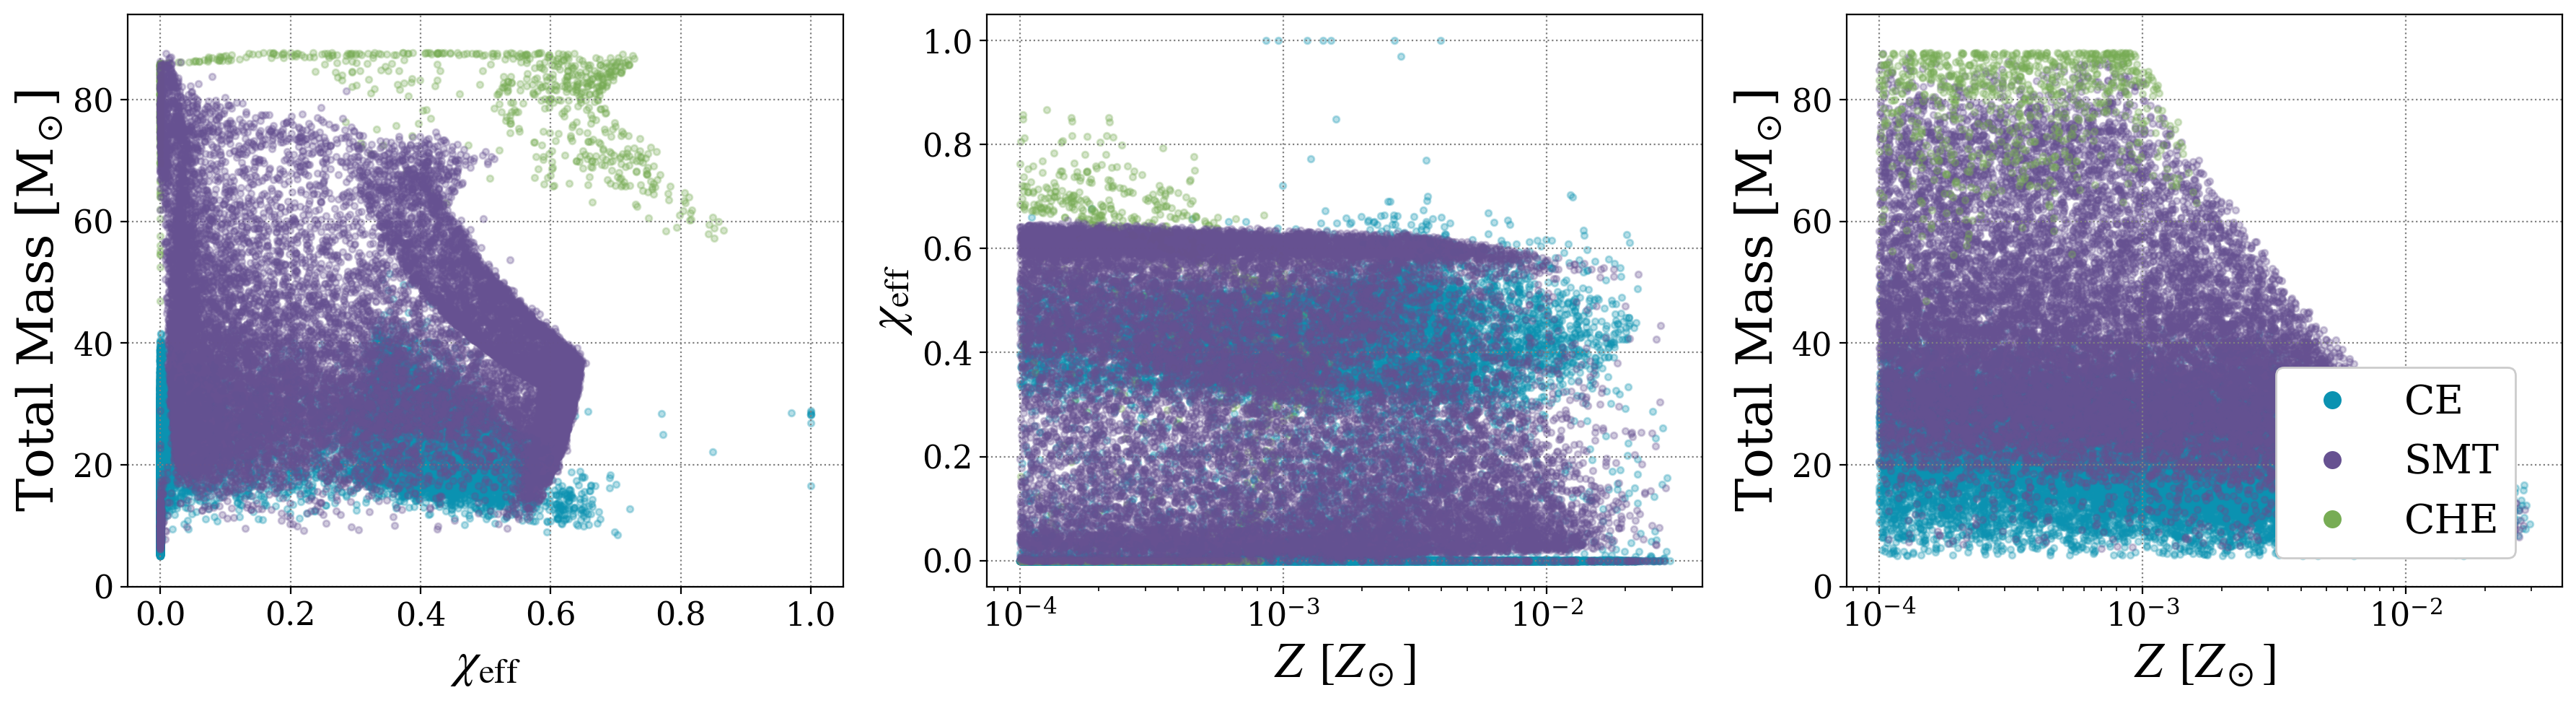

In [42]:
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize



fig, axes = plt.subplots(ncols=3, figsize=(18, 5))

pop_name = 'realistic'
dco_type='BBH'

pop_spin_df = pop_spin_dfs[pop_name]
pop_spin_df = pop_spin_df[(pop_spin_df[dco_type]) & (pop_spin_df["Merges_Hubble_Time"])]
pop_df = pop_spin_df


any_rlof = (pop_df['RLOF_Primary']==True) + (pop_df['RLOF_Secondary']==True) + (pop_df['RLOF_Both']==True)
any_ce = (pop_df['CE_Primary']==True) + (pop_df['CE_Secondary']==True) +(pop_df['CE_Both']==True)
any_che = (pop_df['CH_on_MS(1)']==True) + (pop_df['CH_on_MS(2)']==True)
smt_mask = any_rlof * (~any_ce) * (~any_che)
ce_mask = any_ce * (~any_che)
che_mask = any_che

m1, m2 = pop_df["Mass@DCO(1)"], pop_df["Mass@DCO(2)"]
z1 = pop_df["Metallicity@ZAMS(1)"]
chi_eff_inclination = pop_df['chi_eff']

alpha = 0.3
s = 10

######################################
ax = axes[0]

x_vals = chi_eff_inclination
y_vals = np.minimum(m1,m2) / np.maximum(m1,m2)
y_vals = m1+m2


ax.scatter(x_vals[ce_mask], y_vals[ce_mask], alpha=alpha, s=s, color=colorPalette['blue'], label='CE', zorder=1)
ax.scatter(x_vals[smt_mask], y_vals[smt_mask], alpha=alpha, s=s, color=colorPalette['violet'], label='SMT', zorder=10)
ax.scatter(x_vals[che_mask], y_vals[che_mask], alpha=alpha, s=s, color=colorPalette['green'], label='CHE')

ax.set_xlabel(r'$\chi_{\rm eff}$', fontsize=25)
# ax.set_ylabel(r'$q$', fontsize=25)
ax.set_ylabel('Total Mass [M$_\odot$]', fontsize=25)

# ax.set_ylim(0, 1)
ax.set_ylim(0, 94)
ax.set_xlim(-0.05, 1.05)

ax.grid()

############################################

# Get x and y values
x_vals = z1
y_vals = chi_eff_inclination


ax = axes[1]
ax.scatter(x_vals[ce_mask], y_vals[ce_mask], alpha=alpha, s=s, color=colorPalette['blue'], label='CE', zorder=1)
ax.scatter(x_vals[smt_mask], y_vals[smt_mask], alpha=alpha, s=s, color=colorPalette['violet'], label='SMT', zorder=10)
ax.scatter(x_vals[che_mask], y_vals[che_mask], alpha=alpha, s=s, color=colorPalette['green'], label='CHE')


# ax.set_title(pop_labels[pop_name])
ax.set_xscale('log')
# ax.set_yscale('log')
ax.set_ylabel(r'$\chi_{\rm eff}$', fontsize=25)
ax.set_xlabel(r'$Z$ $[Z_\odot]$', fontsize=25)

ax.set_ylim(-0.05, 1.05)

ax.grid()

######

ax = axes[2]

x_vals = z1
# y_vals = np.minimum(m1,m2) / np.maximum(m1,m2)
y_vals = m1+m2

ax.scatter(x_vals[ce_mask], y_vals[ce_mask], alpha=alpha, s=s, color=colorPalette['blue'], label='CE', zorder=0)
ax.scatter(x_vals[smt_mask], y_vals[smt_mask], alpha=alpha, s=s, color=colorPalette['violet'], label='SMT', zorder=1)
ax.scatter(x_vals[che_mask], y_vals[che_mask], alpha=alpha, s=s, color=colorPalette['green'], label='CHE')

ax.set_xscale('log')
# ax.set_yscale('log')
# ax.set_ylabel(r'$q$', fontsize=25)
ax.set_ylabel('Total Mass [M$_\odot$]', fontsize=25)

ax.set_xlabel(r'$Z$ $[Z_\odot]$', fontsize=25)
ax.set_ylim(0, 94)

ax.grid()

from matplotlib.lines import Line2D

legend_elements = [
Line2D([0], [0], marker='o', color='w', label='CE',
   markerfacecolor=colorPalette['blue'], markersize=10, alpha=1),
Line2D([0], [0], marker='o', color='w', label='SMT',
       markerfacecolor=colorPalette['violet'], markersize=10, alpha=1),
Line2D([0], [0], marker='o', color='w', label='CHE',
       markerfacecolor=colorPalette['green'], markersize=10, alpha=1),
]

axes[2].legend(handles=legend_elements, fontsize=20, loc=(0.6, 0.05))


plt.tight_layout()
plt.savefig(plot_path+"chi_eff_q_met.png", dpi=300, bbox_inches='tight')
plt.show()

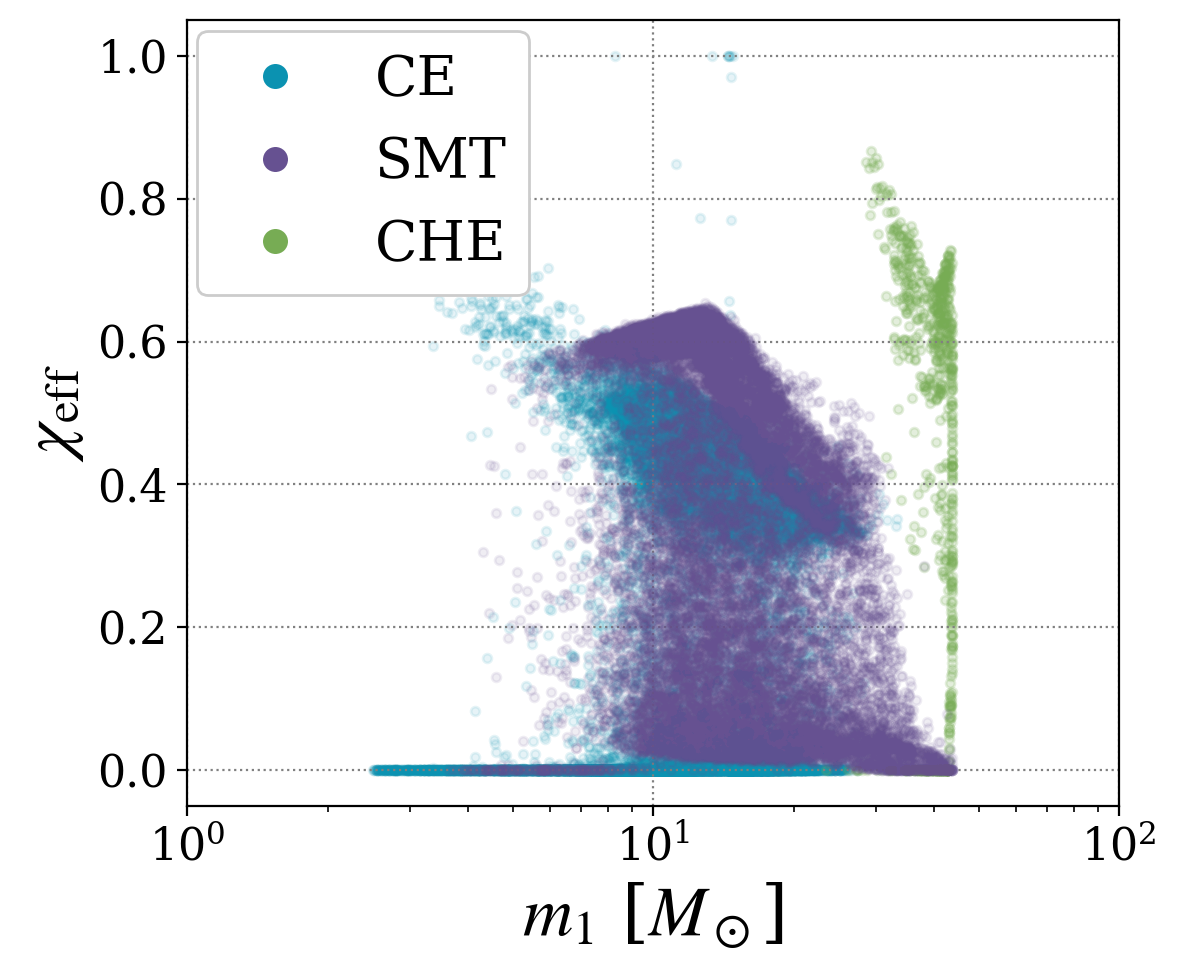

In [43]:
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize



fig, ax = plt.subplots(ncols=1, figsize=(6, 5))

pop_name = 'realistic'
dco_type='BBH'

pop_spin_df = pop_spin_dfs[pop_name]
pop_spin_df = pop_spin_df[(pop_spin_df[dco_type]) & (pop_spin_df["Merges_Hubble_Time"])]
pop_df = pop_spin_df


any_rlof = (pop_df['RLOF_Primary']==True) + (pop_df['RLOF_Secondary']==True) + (pop_df['RLOF_Both']==True)
any_ce = (pop_df['CE_Primary']==True) + (pop_df['CE_Secondary']==True) +(pop_df['CE_Both']==True)
any_che = (pop_df['CH_on_MS(1)']==True) + (pop_df['CH_on_MS(2)']==True)
smt_mask = any_rlof * (~any_ce) * (~any_che)
ce_mask = any_ce * (~any_che)
che_mask = any_che

m1, m2 = pop_df["Mass@DCO(1)"], pop_df["Mass@DCO(2)"]
z1 = pop_df["Metallicity@ZAMS(1)"]
chi_eff_inclination = pop_df['chi_eff']

alpha = 0.1
s = 10

######################################

y_vals = chi_eff_inclination
x_vals = m1

ax.scatter(x_vals[ce_mask], y_vals[ce_mask], alpha=alpha, s=s, color=colorPalette['blue'], label='CE', zorder=1)
ax.scatter(x_vals[smt_mask], y_vals[smt_mask], alpha=alpha, s=s, color=colorPalette['violet'], label='SMT', zorder=10)
ax.scatter(x_vals[che_mask], y_vals[che_mask], alpha=2*alpha, s=s, color=colorPalette['green'], label='CHE')

ax.set_ylabel(r'$\chi_{\rm eff}$', fontsize=25)
ax.set_xlabel('$m_{1}$ [$M_\odot$]', fontsize=25)

# ax.set_ylim(0, 1)
ax.set_xlim(1, 100)
ax.set_ylim(-0.05, 1.05)
ax.set_xscale('log')

ax.grid()

from matplotlib.lines import Line2D

legend_elements = [
Line2D([0], [0], marker='o', color='w', label='CE',
   markerfacecolor=colorPalette['blue'], markersize=10, alpha=1),
Line2D([0], [0], marker='o', color='w', label='SMT',
       markerfacecolor=colorPalette['violet'], markersize=10, alpha=1),
Line2D([0], [0], marker='o', color='w', label='CHE',
       markerfacecolor=colorPalette['green'], markersize=10, alpha=1),
]

ax.legend(handles=legend_elements, fontsize=20, loc=(0.01, 0.65))


plt.tight_layout()
plt.show()